# Pipeline completo — OCR + modelo, num único notebook

Passe **um arquivo** (PDF ou imagem) e **qual modelo** usar, rode as células, e receba as entidades encontradas direto na saída do notebook. Nada é salvo em disco (nem a extração do OCR, nem o resultado final) — tudo fica só na memória desta sessão do Jupyter, pra rodar rapidinho sem sujar `data/`.

Roda os dois estágios incompatíveis (OCR no `.venv_ocr` / modelo no `.venv` geral) numa única execução. Este notebook roda inteiro no kernel do venv **GERAL** (torch/transformers) — o estágio de OCR é feito chamando `scripts/extrair_ocr_worker.py` como um **processo separado**, usando o interpretador Python do `.venv_ocr` explicitamente (`subprocess`), com o JSON de extração escrito num arquivo **temporário** (apagado ao final). Nunca importa `paddleocr` neste kernel, evitando o conflito de cuDNN (WinError 127) documentado em `requirements_ocr.txt`.

Aceita qualquer **PDF** (nativo, escaneado, ou uma mistura das duas coisas página a página) ou **imagem** — o worker decide nativo/OCR por página sozinho.

**Pré-requisitos:**
- Kernel do venv **GERAL** do projeto (`.venv`, torch/transformers) selecionado no Jupyter.
- `.venv_ocr` já criado em disco (ver `requirements_ocr.txt`) — não precisa estar selecionado/ativo aqui, só existir; é chamado via subprocess.


In [15]:
import json
import subprocess
import sys
import tempfile
from io import BytesIO
from pathlib import Path

import fitz  # PyMuPDF
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from transformers import AutoModel, AutoModelForTokenClassification, AutoTokenizer

print(f"CUDA disponível: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


CUDA disponível: True


## Configuração — preencha o arquivo e o modelo aqui

In [16]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")

RAIZ = encontrar_raiz_projeto()
sys.path.insert(0, str(RAIZ / "scripts"))
from pos_processamento_ner import (
    extrair_nome_assinatura_digital,
    propagar_entidades_por_texto_identico,
    mesclar_previsoes_por_janela,
)

# --- 1) Aponte para QUALQUER arquivo -- PDF (nativo, escaneado, ou misto) ou imagem ---
CAMINHO_ARQUIVO = fr"D:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\teste_holdout\arquivos\cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf.pdf"  # NOVA MEDICAL -- caso do bug de NOME trocado (troca [NOME_2R5F2] por [NOME_AU08L] na pergunta de endereço)

# --- 2) Escolha o modelo ---
ARQUITETURA = "4cabecas"  # Modelo 6 (o mesmo usado no rerun_comparacao_holdout, onde o bug foi encontrado)
INCLUIR_SINTETICOS = False
CENARIO_MANUAL = "c06_sem_weight_decay"  # mesmo cenário do "Avaliar TODOS os modelos - holdout.ipynb" (melhor F1/bbox no holdout)

# --- 3) Pós-processamento ---
APLICAR_REGEX_ASSINATURA_DIGITAL = True
APLICAR_PROPAGACAO_TEXTO_IDENTICO = True

MAX_LENGTH = 512
TIPOS = ["CPF", "RG", "NOME", "ENDERECO"]

_sufixo_experimento = "-com-sinteticos" if INCLUIR_SINTETICOS else "-sem-sinteticos"
_nome_pasta_modelo = "bertimbau-pii-v1-cenarios" if ARQUITETURA == "1cabeca" else "bertimbau-4cabecas-pii-v1-cenarios"
PASTA_CENARIOS = RAIZ / "models" / f"{_nome_pasta_modelo}{_sufixo_experimento}"

resultados_cenarios = json.loads((PASTA_CENARIOS / "_comparacao_cenarios.json").read_text(encoding="utf-8"))
cenario_escolhido = next((r for r in resultados_cenarios if r["nome"] == CENARIO_MANUAL), resultados_cenarios[0]) if CENARIO_MANUAL else resultados_cenarios[0]

print(f"Arquivo:     {CAMINHO_ARQUIVO}")
print(f"Existe?      {Path(CAMINHO_ARQUIVO).exists()}")
print(f"Arquitetura: {ARQUITETURA}")
print(f"Experimento: {PASTA_CENARIOS.name}")
print(f"Cenário:     {cenario_escolhido['nome']} (F1 token-level={cenario_escolhido['eval_f1']:.4f})")


Arquivo:     D:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\teste_holdout\arquivos\cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf.pdf
Existe?      True
Arquitetura: 4cabecas
Experimento: bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos
Cenário:     c06_sem_weight_decay (F1 token-level=0.6969)


## Estágio 1 — Extração (OCR via subprocess no `.venv_ocr`)

Chama `scripts/extrair_ocr_worker.py` com o interpretador do venv isolado, explicitamente — roda como um processo à parte, nunca importa `paddleocr` neste kernel. O JSON de extração é escrito num diretório **temporário** e carregado direto na memória (`extracao`) -- nada fica salvo em `data/` depois que a célula termina.

In [17]:
def localizar_python_venv_ocr() -> Path:
    candidatos = [
        RAIZ / ".venv_ocr" / "Scripts" / "python.exe",  # Windows
        RAIZ / ".venv_ocr" / "bin" / "python",           # Linux/Mac
    ]
    for c in candidatos:
        if c.exists():
            return c
    raise FileNotFoundError(
        f"Não encontrei o interpretador do venv de OCR em nenhum de: {candidatos}. "
        f"Crie o venv isolado primeiro (ver requirements_ocr.txt)."
    )


caminho_arquivo = Path(CAMINHO_ARQUIVO)
if not caminho_arquivo.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_arquivo}")

python_ocr = localizar_python_venv_ocr()
worker = RAIZ / "scripts" / "extrair_ocr_worker.py"

print(f"Rodando extração ({python_ocr.parent.parent.name})...")
with tempfile.TemporaryDirectory() as pasta_tmp:
    caminho_json_tmp = Path(pasta_tmp) / f"{caminho_arquivo.name}.json"
    resultado_proc = subprocess.run(
        [str(python_ocr), str(worker), str(caminho_arquivo), str(caminho_json_tmp)],
        capture_output=True, text=True,
    )
    if resultado_proc.stderr:
        print(resultado_proc.stderr.strip())
    if resultado_proc.returncode != 0:
        raise RuntimeError(
            f"Extração falhou (código {resultado_proc.returncode}).\nstdout: {resultado_proc.stdout}\nstderr: {resultado_proc.stderr}"
        )
    extracao = json.loads(caminho_json_tmp.read_text(encoding="utf-8"))
# pasta_tmp (e o JSON dentro dela) já foi apagada aqui -- só "extracao" (em memória) sobrevive.

n_paginas = len(extracao["pages"])
n_tokens = sum(len(p["tokens"]) for p in extracao["pages"])
print(f"\nDocumento: {extracao['document_id']} -- {n_paginas} página(s), {n_tokens} token(s) no total.")


Rodando extração (.venv_ocr)...
Carregando PaddleOCR...
INFORMA€åES: nÆo foi poss¡vel localizar arquivos para o(s) padrÆo(äes) especificado(s).
d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv_ocr\lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:717: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Paddle compilado com CUDA: True | GPUs detectadas: 1
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Gabriel-PC\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Gabriel-PC\.paddlex\official_models\PP-OCRv6_medium_rec`.


## Estágio 2 — Carrega o modelo escolhido (`ARQUITETURA`) e roda a inferência (com chunking)

In [18]:
def agrupar_bboxes_por_linha(tokens_bbox: list, indices: list) -> list:
    if not indices:
        return []
    grupos = []
    grupo_atual = [tokens_bbox[indices[0]]]
    y_ref = tokens_bbox[indices[0]][1]
    for i in indices[1:]:
        bbox = tokens_bbox[i]
        altura_ref = grupo_atual[-1][3] - grupo_atual[-1][1]
        if abs(bbox[1] - y_ref) > max(altura_ref * 0.6, 3):
            grupos.append(grupo_atual)
            grupo_atual = [bbox]
            y_ref = bbox[1]
        else:
            grupo_atual.append(bbox)
    grupos.append(grupo_atual)
    return [[min(b[0] for b in g), min(b[1] for b in g), max(b[2] for b in g), max(b[3] for b in g)] for g in grupos]


def bbox_externo(lista_bboxes: list):
    if not lista_bboxes:
        return None
    return [min(b[0] for b in lista_bboxes), min(b[1] for b in lista_bboxes),
            max(b[2] for b in lista_bboxes), max(b[3] for b in lista_bboxes)]


def iou(a, b) -> float:
    if a is None or b is None:
        return 0.0
    xi0, yi0 = max(a[0], b[0]), max(a[1], b[1])
    xi1, yi1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, xi1 - xi0) * max(0, yi1 - yi0)
    if inter == 0:
        return 0.0
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    uniao = area_a + area_b - inter
    return inter / uniao if uniao > 0 else 0.0


if ARQUITETURA == "1cabeca":
    LABEL_LIST = ["O"] + [f"{p}-{t}" for t in TIPOS for p in ("B", "I")]
    ID2LABEL = {i: l for i, l in enumerate(LABEL_LIST)}

    tokenizer = AutoTokenizer.from_pretrained(cenario_escolhido["pasta_modelo"])
    model = AutoModelForTokenClassification.from_pretrained(cenario_escolhido["pasta_modelo"]).to(device)
    model.eval()

    def decodificar_bio(tags_previstas: list, tokens_bbox: list, tokens: list) -> list:
        entidades = []
        i, n = 0, len(tags_previstas)
        while i < n:
            tag = tags_previstas[i]
            if tag == "O":
                i += 1
                continue
            tipo = tag.split("-", 1)[1]
            indices = [i]
            j = i + 1
            while j < n and tags_previstas[j] == f"I-{tipo}":
                indices.append(j)
                j += 1
            entidades.append({
                "type": tipo,
                "bbox": agrupar_bboxes_por_linha(tokens_bbox, indices),
                "indices": indices,
                "text": " ".join(tokens[k] for k in indices),
            })
            i = j
        return entidades

    @torch.no_grad()
    def _prever_tags_janela(tokens_janela: list) -> list:
        encoding = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        encoding = {k: v.to(device) for k, v in encoding.items() if k in ("input_ids", "attention_mask")}
        logits = model(**encoding).logits[0]
        pred_ids = logits.argmax(dim=-1).tolist()
        word_ids = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()
        tags = ["O"] * len(tokens_janela)
        visto = set()
        for pid, wid in zip(pred_ids, word_ids):
            if wid is None or wid in visto:
                continue
            visto.add(wid)
            tags[wid] = ID2LABEL[pid]
        return tags

    def prever_pagina(tokens: list, tokens_bbox: list) -> list:
        if not tokens:
            return []
        tags = mesclar_previsoes_por_janela(tokens, tokenizer, _prever_tags_janela, max_length=MAX_LENGTH)
        return decodificar_bio(tags, tokens_bbox, tokens)

else:  # ARQUITETURA == "4cabecas"
    LABEL2ID_POR_TIPO = {t: {"O": 0, f"B-{t}": 1, f"I-{t}": 2} for t in TIPOS}
    ID2LABEL_POR_TIPO = {t: {v: k for k, v in LABEL2ID_POR_TIPO[t].items()} for t in TIPOS}

    class BERTimbau4Cabecas(nn.Module):
        """Mesma definição de notebooks/bert_4_cabecas/06 -- reproduzida aqui por autocontenção."""

        def __init__(self, checkpoint_base: str, tipos: list):
            super().__init__()
            self.tipos = list(tipos)
            self.encoder = AutoModel.from_pretrained(checkpoint_base)
            hidden = self.encoder.config.hidden_size
            p_dropout = getattr(self.encoder.config, "hidden_dropout_prob", 0.1)
            self.dropout = nn.Dropout(p_dropout)
            self.cabecas = nn.ModuleDict({t: nn.Linear(hidden, 3) for t in self.tipos})

        def forward(self, input_ids, attention_mask):
            saida_encoder = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
            oculto = self.dropout(saida_encoder.last_hidden_state)
            return {"logits_por_tipo": {t: self.cabecas[t](oculto) for t in self.tipos}}

        @classmethod
        def load(cls, pasta, device):
            pasta = Path(pasta)
            config = json.loads((pasta / "config_4cabecas.json").read_text(encoding="utf-8"))
            modelo = cls(str(pasta / "encoder"), config["tipos"])
            cabecas_state = torch.load(pasta / "cabecas.pt", map_location=device)
            for t in config["tipos"]:
                modelo.cabecas[t].load_state_dict(cabecas_state[t])
            return modelo.to(device)

    tokenizer = AutoTokenizer.from_pretrained(Path(cenario_escolhido["pasta_modelo"]) / "encoder")
    model = BERTimbau4Cabecas.load(cenario_escolhido["pasta_modelo"], device=device)
    model.eval()

    @torch.no_grad()
    def _prever_tags_janela_tipo(tokens_janela: list, tipo: str) -> list:
        encoding = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        # BERTimbau4Cabecas.forward só aceita input_ids/attention_mask -- filtra
        # token_type_ids, que o tokenizer devolve por padrão (bug encontrado 2026-09-15).
        encoding = {k: v.to(device) for k, v in encoding.items() if k in ("input_ids", "attention_mask")}
        saida = model(**encoding)
        pred_ids = saida["logits_por_tipo"][tipo][0].argmax(dim=-1).tolist()
        word_ids = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()
        tags = ["O"] * len(tokens_janela)
        visto = set()
        for pid, wid in zip(pred_ids, word_ids):
            if wid is None or wid in visto:
                continue
            visto.add(wid)
            tags[wid] = ID2LABEL_POR_TIPO[tipo][pid]
        return tags

    def prever_pagina(tokens: list, tokens_bbox: list) -> list:
        if not tokens:
            return []
        entidades = []
        for tipo in TIPOS:
            tags = mesclar_previsoes_por_janela(
                tokens, tokenizer, lambda tj, t=tipo: _prever_tags_janela_tipo(tj, t), max_length=MAX_LENGTH
            )
            i, n = 0, len(tags)
            while i < n:
                if tags[i] == "O":
                    i += 1
                    continue
                indices = [i]
                j = i + 1
                while j < n and tags[j] == f"I-{tipo}":
                    indices.append(j)
                    j += 1
                entidades.append({
                    "type": tipo,
                    "bbox": agrupar_bboxes_por_linha(tokens_bbox, indices),
                    "indices": indices,
                    "text": " ".join(tokens[k] for k in indices),
                })
                i = j
        return entidades

print(f"Modelo carregado ({ARQUITETURA}): {cenario_escolhido['nome']}")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8556.12it/s]

Modelo carregado (4cabecas): c06_sem_weight_decay


## Roda a inferência + pós-processamento -- resultado final

Nada é salvo em disco aqui -- `entidades_documento` fica só na memória desta sessão, e a lista completa é impressa abaixo.

In [19]:
entidades_documento = []

for pagina_dados in extracao["pages"]:
    tokens_dict = pagina_dados["tokens"]
    if not tokens_dict:
        continue
    tokens = [t["text"] for t in tokens_dict]
    tokens_bbox = [t["bbox"] for t in tokens_dict]

    previstas = prever_pagina(tokens, tokens_bbox)

    if APLICAR_REGEX_ASSINATURA_DIGITAL:
        extras = extrair_nome_assinatura_digital(tokens, tokens_bbox)
        for extra in extras:
            bbox_extra = bbox_externo(extra["bbox"])
            ja_coberto = any(
                p["type"] == "NOME" and iou(bbox_extra, bbox_externo(p["bbox"])) > 0.1
                for p in previstas
            )
            if not ja_coberto:
                previstas.append(extra)

    for p in previstas:
        p["page"] = pagina_dados["page"]
    entidades_documento.extend(previstas)

if APLICAR_PROPAGACAO_TEXTO_IDENTICO:
    entidades_documento = propagar_entidades_por_texto_identico(
        entidades_documento, extracao["pages"], tipos_propagaveis=tuple(TIPOS)
    )

entidades_documento = sorted(entidades_documento, key=lambda x: (x["page"], x["type"]))

print(f"{extracao['document_id']} ({ARQUITETURA}, {cenario_escolhido['nome']}) -- {len(entidades_documento)} entidade(s) encontrada(s)\n")
for e in entidades_documento:
    origem = f" [{e['origem']}]" if "origem" in e else ""
    print(f"  p{e['page']:<3} {e['type']:<9} \"{e['text']}\"{origem}")


cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf (4cabecas, c06_sem_weight_decay) -- 36 entidade(s) encontrada(s)

  p1   NOME      "Marinely de Paula Bomfim" [propagado_texto_identico]
  p1   NOME      "Marinely de Paula Bomfim" [propagado_texto_identico]
  p2   CPF       "509.541.132-68"
  p2   NOME      "ALEXANDRE JOU LYCHATCHYNSKY BASTOS"
  p2   NOME      "Marinely de Paula Bomfim"
  p2   NOME      "Marinely de Paula Bomfim" [propagado_texto_identico]
  p3   CPF       "509.541.132-68,"
  p3   ENDERECO  "Rua Mato Grosso nº. 1430, apartamento 402, Bairro Centro, CEP nº. 35500-027, portador da Cédula de Identidade nº. 5.606.626-8"
  p3   NOME      "ALEXANDRE JOU LYCHATCHYNSKY BASTOS,"
  p3   NOME      "Jozino de Maciel Bastos"
  p3   NOME      "Daria Lychatchynsky,"
  p3   NOME      "Marinely de Paula Bomfim"
  p3   NOME      "Marinely de Paula Bomfim" [propagado_texto_identico]
  p4   NOME      "Alexandre Jou Lychatchynsky Bastos"
  p4   NOME      "Marinely de Paula Bomfim"

## Visualização (opcional): páginas com as caixas previstas

Só exibe (`plt.show()`) -- não salva imagem nenhuma em disco. Preencha `PAGINA_UNICA` com um número para ver só uma página, ou deixe `None` para ver o documento inteiro.

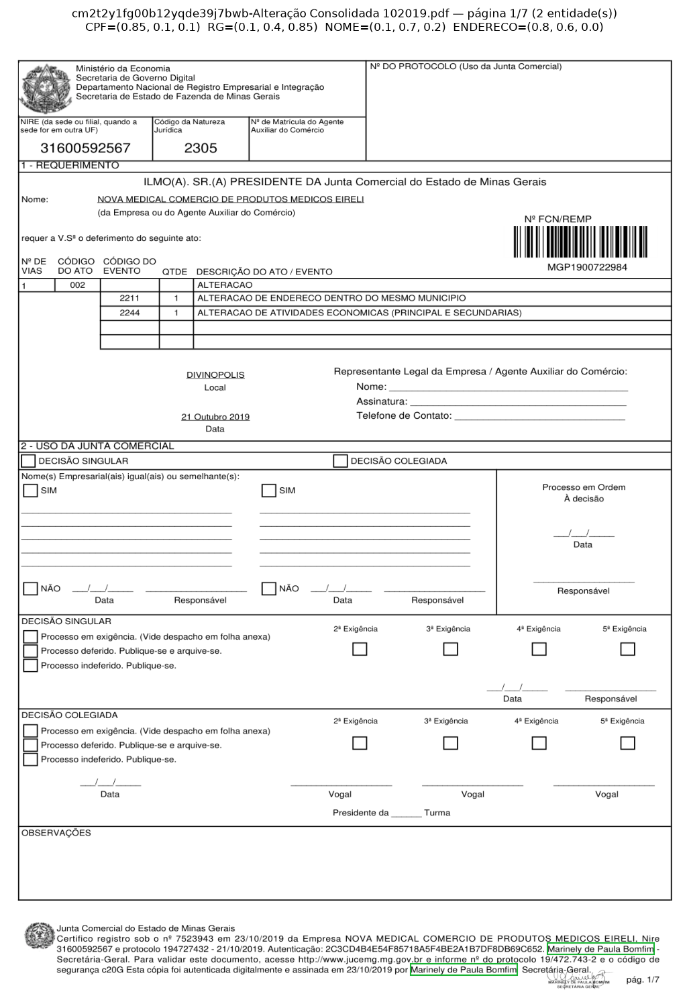

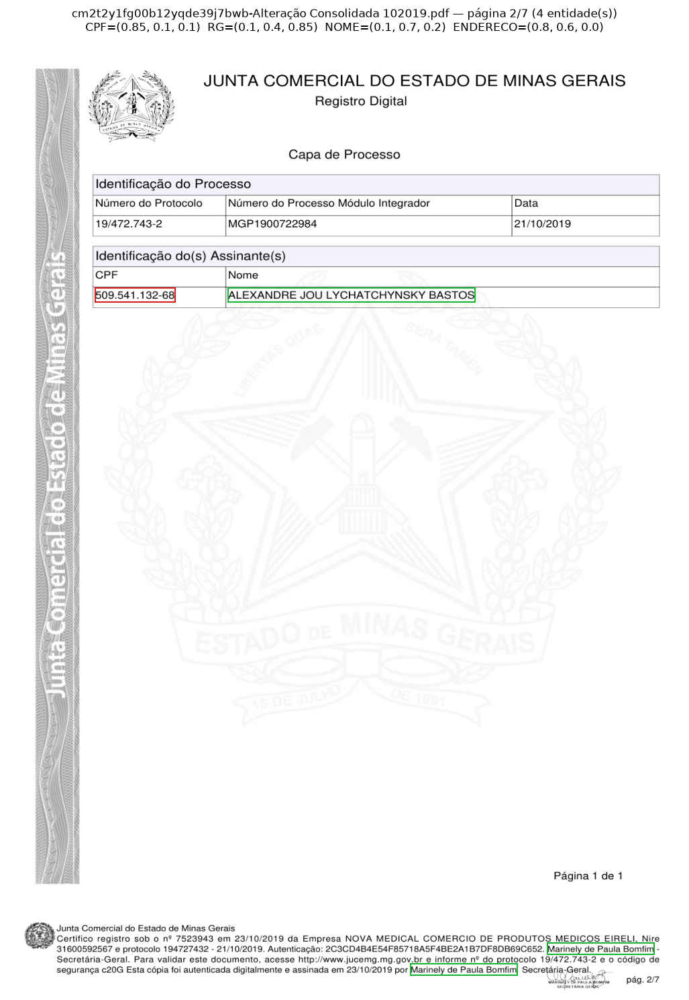

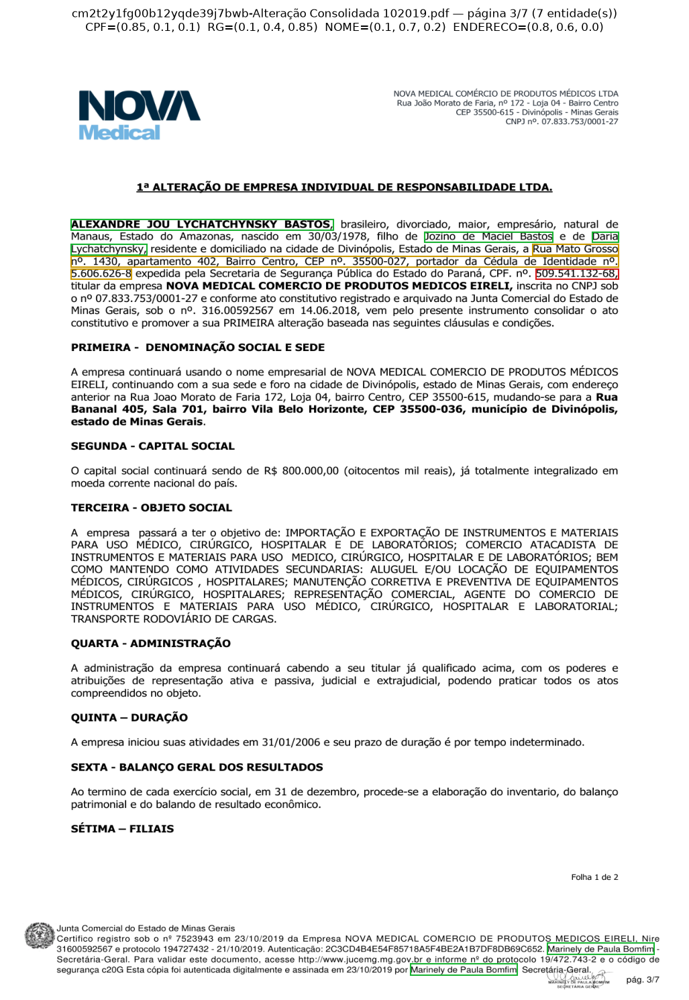

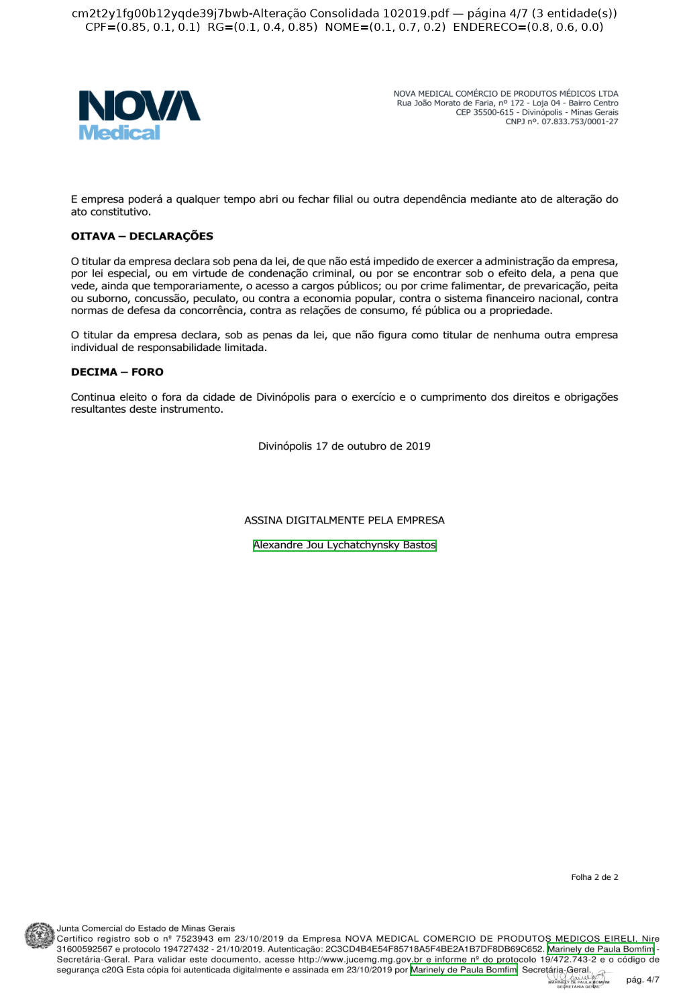

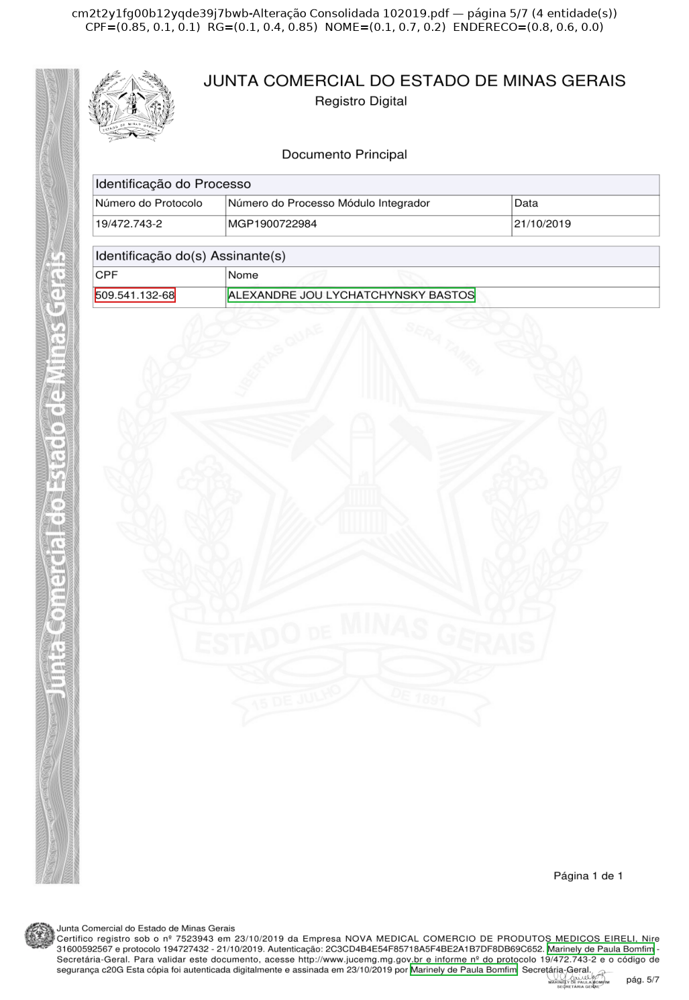

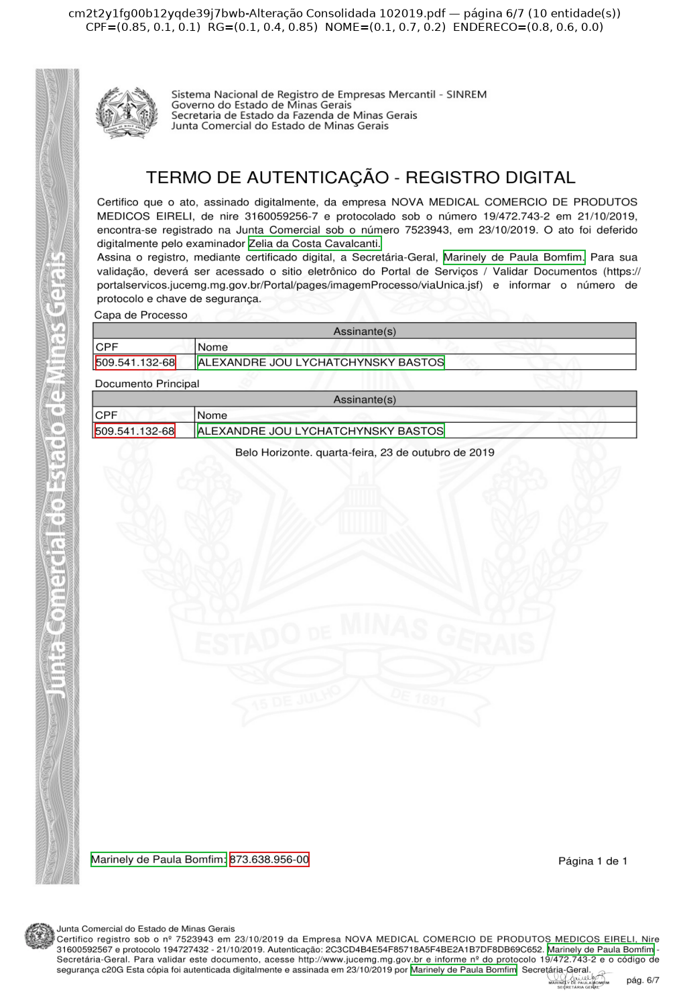

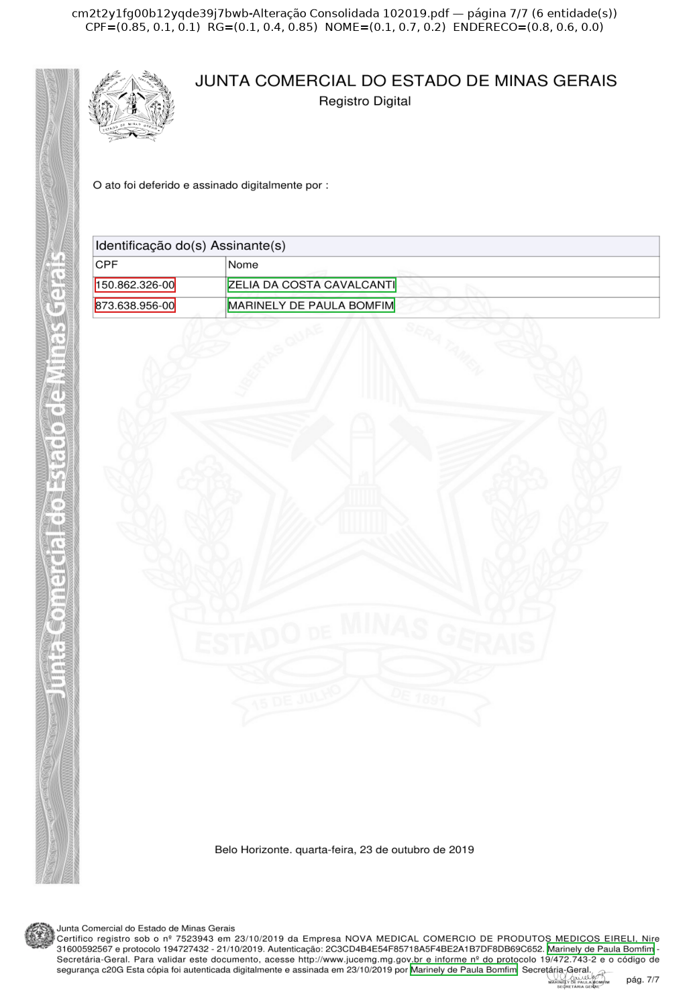

In [20]:
CORES_POR_TIPO = {
    "CPF": (0.85, 0.1, 0.1),
    "RG": (0.1, 0.4, 0.85),
    "NOME": (0.1, 0.7, 0.2),
    "ENDERECO": (0.8, 0.6, 0.0),
}
PAGINA_UNICA = None  # ex: 3 -- None mostra todas as páginas
DPI_VISUALIZACAO = 150

EXTENSOES_IMAGEM_VIS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
legenda = "  ".join(f"{t}={c}" for t, c in CORES_POR_TIPO.items())


def desenhar_pagina(imagem_base, entidades_pagina, titulo):
    # Desenha os bbox por cima da imagem via matplotlib (em vez de page.draw_rect, que só
    # funciona em documento PDF de verdade -- Shape.__init__ do PyMuPDF recusa imagem com
    # "ValueError: is no PDF").
    fig, ax = plt.subplots(figsize=(11, 15))
    ax.imshow(imagem_base)
    for e in entidades_pagina:
        cor = CORES_POR_TIPO.get(e["type"], (0, 0, 0))
        # Um retângulo por linha de e["bbox"] -- bbox_externo() (um retângulo único
        # cobrindo todas as linhas) faz o desenho "vazar" para a esquerda quando a
        # entidade quebra linha e a 2ª linha começa mais à esquerda que a 1ª (achado
        # 2026-09-15, caso MINAS CAL/endereço do Sérgio).
        for retangulo in (e["bbox"] or []):
            x0, y0, x1, y1 = retangulo
            ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=1.5, edgecolor=cor, facecolor="none"))
    ax.axis("off")
    ax.set_title(f"{titulo}\n{legenda}")
    plt.tight_layout()
    plt.show()


if caminho_arquivo.suffix.lower() in EXTENSOES_IMAGEM_VIS:
    imagem_base = Image.open(caminho_arquivo)
    entidades_pagina = [e for e in entidades_documento if e["page"] == 1]
    desenhar_pagina(
        imagem_base, entidades_pagina,
        f"{extracao['document_id']} ({len(entidades_pagina)} entidade(s))",
    )
else:
    doc_pdf = fitz.open(caminho_arquivo)
    escala_pdf_para_pixel = DPI_VISUALIZACAO / 72.0
    paginas_para_mostrar = [PAGINA_UNICA] if PAGINA_UNICA else range(1, doc_pdf.page_count + 1)

    for numero_pagina in paginas_para_mostrar:
        pagina_pdf = doc_pdf[numero_pagina - 1]
        entidades_pagina = [e for e in entidades_documento if e["page"] == numero_pagina]

        pix = pagina_pdf.get_pixmap(dpi=DPI_VISUALIZACAO)
        imagem_base = Image.open(BytesIO(pix.tobytes("png")))

        entidades_pagina_px = [
            {**e, "bbox": [[c * escala_pdf_para_pixel for c in caixa] for caixa in e["bbox"]]}
            for e in entidades_pagina
        ]
        desenhar_pagina(
            imagem_base, entidades_pagina_px,
            f"{extracao['document_id']} — página {numero_pagina}/{doc_pdf.page_count} ({len(entidades_pagina)} entidade(s))",
        )
    doc_pdf.close()


## Estágio 3 — Mascarar o documento e comparar respostas do Gemini (original × mascarado)

Desenha um retângulo preenchido + um marcador tipo `[TIPO_número]` (ex.: `[NOME_1]`, `[CPF_2]`) sobre cada entidade detectada. **Tudo é enviado ao Gemini como imagem (raster), nunca como PDF** — tanto o documento original quanto o mascarado passam pela mesma renderização (`page.get_pixmap`). Isso dá a garantia mais forte possível contra vazamento: uma imagem não tem camada de texto nenhuma por baixo pra "escapar" da máscara.

Duas entidades com o mesmo tipo e o mesmo texto (ex.: o mesmo nome citado em duas páginas) recebem **o mesmo marcador** — o catálogo é por valor distinto, não por ocorrência.

A comparação em si (perguntar × mascarar × desmascarar × imprimir) fica dentro de uma única função, `perguntar_com_e_sem_mascara(caminho_arquivo, pergunta, mostrar_documento=True)` — assim dá pra chamá-la várias vezes seguidas, uma por pergunta, sem repetir a lógica. Cada chamada:
1. Envia `pergunta` ao Gemini com o documento **original**.
2. Envia `pergunta + observação de mascaramento` ao Gemini com o documento **mascarado**.
3. Desmascara a resposta da versão mascarada (troca os marcadores pelos valores reais).
4. Se `mostrar_documento=True` (padrão), mostra cada página do documento com **original e mascarado lado a lado**; sempre imprime as duas respostas. Use `mostrar_documento=False` em chamadas repetidas sobre o mesmo documento pra não reimprimir as mesmas imagens a cada pergunta.

Nada é salvo em disco — as imagens (originais e mascaradas) ficam num diretório temporário, apagado ao final de cada chamada.

**Guardrail (achado 2026-09-15):** `OBSERVACAO_MASCARAMENTO` também instrui o Gemini a recusar explicitamente perguntas que exijam comparar um valor REAL escrito na própria pergunta (um nome, CPF, endereço etc.) contra os marcadores mascarados -- ex.: "Fulano é sócio da empresa?" ou "esse endereço é de um dos sócios?". Sem valor real algum por trás dos marcadores, o Gemini não tem como verificar essa comparação -- e sem essa instrução, ele podia "chutar" uma resposta em vez de admitir isso. É uma defesa em nível de prompt (não uma checagem programática) -- confira sempre a resposta mascarada BRUTA (impressa abaixo) pra confirmar que o guardrail realmente se manteve.

**Mapa de páginas por marcador (achado 2026-09-17):** um teste real revelou que, mesmo com o marcador certo perfeitamente legível bem ao lado do nome da pessoa na imagem, o Gemini às vezes associa o endereço errado -- puxando um marcador que se repete várias vezes no documento (ex.: um endereço institucional no rodapé de 5 páginas) em vez do marcador correto, que aparece só uma vez, ao lado do nome. Provável viés de frequência, não de leitura. Corrigido enviando, junto com a pergunta mascarada, um mapa explícito de em quais páginas cada marcador aparece -- com aviso de que marcadores repetidos em 3+ páginas são provavelmente cabeçalho/rodapé institucional -- e instrução para seguir a ordem/posição do texto, não a frequência.

**Pré-requisito:** `pip install google-genai python-dotenv` e `GEMINI_API_KEY` definida (variável de ambiente, ou um arquivo `.env` na raiz do projeto).

In [21]:
import os
import shutil
import time

from google import genai
from google.genai import types
from PIL import ImageDraw, ImageFont

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass


MODEL_GEMINI = "gemini-2.5-flash"

# Complemento de prompt sobre o esquema de mascaramento -- centralizado em prompts/mascaramento_observacao.txt
# pra todos os notebooks que perguntam sobre documento mascarado (este e
# notebooks/rerun_comparacao_holdout/pipeline_completo_holdout.ipynb) usarem exatamente o mesmo
# texto, em vez de cada um manter sua própria cópia colada inline.
PASTA_PROMPTS = RAIZ / "prompts"
OBSERVACAO_MASCARAMENTO = "\n\n" + (PASTA_PROMPTS / "mascaramento_observacao.txt").read_text(encoding="utf-8")

api_key = os.environ.get("GEMINI_API_KEY")
if not api_key:
    raise SystemExit("Defina GEMINI_API_KEY (variável de ambiente ou arquivo .env na raiz do projeto) antes de continuar.")

client = genai.Client(api_key=api_key)

# preço por 1.000.000 de tokens, em USD -- conferir em https://ai.google.dev/pricing antes de
# rodar em escala (valores podem estar desatualizados)
PRECOS_GEMINI = {
    "gemini-2.5-pro": {"entrada": 1.25, "saida": 10.00},
    "gemini-2.5-flash": {"entrada": 0.30, "saida": 2.50},
    "gemini-2.5-flash-lite": {"entrada": 0.10, "saida": 0.40},
}


def calcular_custo_gemini(model: str, tokens_entrada: int, tokens_saida: int) -> float:
    precos = PRECOS_GEMINI.get(model)
    if precos is None:
        return float("nan")
    return (tokens_entrada / 1_000_000) * precos["entrada"] + (tokens_saida / 1_000_000) * precos["saida"]


print(f"Modelo Gemini: {MODEL_GEMINI}")

Modelo Gemini: gemini-2.5-flash


## Constrói o catálogo de marcadores e renderiza o documento como imagens (original e mascarada)

In [ ]:
def nome_ascii_seguro(nome: str) -> str:
    import re
    import unicodedata
    limpo = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    limpo = re.sub(r"[^A-Za-z0-9._-]+", "_", limpo).strip("_")
    return limpo or "documento"


_EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
DPI_ENVIO_GEMINI = 200      # qualidade suficiente pra ler CPF/RG pequenos sem inflar demais o custo de tokens
TAMANHO_FONTE_MARCADOR = 20  # tamanho fixo (px, na resolução de DPI_ENVIO_GEMINI) -- legível mesmo
                             # em cima de um token pequeno (ver construir_imagens_mascaradas)

# Um marcador por VALOR distinto de entidade, tipo [TIPO_sufixo]. Duas entidades com o MESMO
# tipo e o MESMO valor (ex.: "SÉRGIO LÚCIO SOARES" citado em várias páginas) recebem o MESMO
# marcador -- sem isso, a mesma pessoa apareceria com marcadores diferentes em lugares
# diferentes, o Gemini interpretaria como pessoas DISTINTAS (achado real 2026-09-15: rodando
# contra o MINAS CAL, "SÉRGIO LÚCIO SOARES," / "Sérgio Lúcio Soares" / "SERGIO LUCIO SOARES" /
# "SÉRGIO LÚCIO SOARES" viraram 4 marcadores diferentes -- comparação por string exata não pega
# maiúscula/minúscula, acento (o bloco de assinatura digital grava sem acento, a qualificação
# com acento) nem pontuação de borda ("Soares," vs "Soares"). A resposta mascarada saiu de fato
# confusa por causa disso -- o próprio Gemini "desconfiou" que os marcadores eram a mesma pessoa
# e chegou a misturar um nome completamente diferente (funcionária da Junta Comercial) com os
# sócios.
#
# Corrigido comparando por uma CHAVE NORMALIZADA (maiúsculas, sem acento, sem pontuação de
# borda -- mesma técnica de `_normalizar_token` em scripts/pos_processamento_ner.py), não a
# string bruta. O marcador exibido/usado no desmascaramento continua usando o texto ORIGINAL da
# primeira ocorrência (ordem de leitura do documento) -- só a comparação é normalizada.
#
# SUFIXO ALEATÓRIO, não sequencial -- achado real 2026-09-17 (mesmo documento MINAS CAL): com
# numeração sequencial (NOME_1, RG_1, CPF_1, ...) numerada INDEPENDENTEMENTE por tipo, a
# Elizabeth calhou de ser RG_1 mas CPF_2 (o CPF dela aparece pela 1ª vez no documento DEPOIS do
# CPF do Sérgio, embora o RG dela apareça antes do RG dele) -- e o Gemini, ao montar uma
# resposta que junta vários campos da mesma pessoa, trocou os CPFs entre as duas pessoas, com o
# padrão exato de "achar" que RG_1 e CPF_1 deviam ser da mesma pessoa (Elizabeth recebeu CPF_1,
# que era do Sérgio; Sérgio recebeu CPF_2, que era dela). Ou seja: o próprio número virou um
# atalho de raciocínio incorreto (número igual => mesma pessoa), quando na verdade a numeração
# de cada tipo é independente e não tem relação nenhuma com a de outro tipo. Trocar por um
# SUFIXO ALEATÓRIO (5 caracteres alfanuméricos, sem relação numérica sequencial) elimina esse
# atalho na raiz -- não existe mais um "número" pra bater entre tipos.
import random
import re
import string
import unicodedata
from collections import defaultdict

_ALFABETO_SUFIXO_MARCADOR = string.ascii_uppercase + string.digits
_TAMANHO_SUFIXO_MARCADOR = 5


def _gerar_sufixo_marcador(sufixos_usados: set) -> str:
    # Sufixo alfanumérico aleatório, único no documento (verifica contra `sufixos_usados`, que é
    # compartilhado entre TODOS os tipos -- não só dentro do mesmo tipo -- pra garantir que
    # nenhum sufixo se repete em lugar nenhum, mesmo entre tipos diferentes).
    while True:
        sufixo = "".join(random.choices(_ALFABETO_SUFIXO_MARCADOR, k=_TAMANHO_SUFIXO_MARCADOR))
        if sufixo not in sufixos_usados:
            sufixos_usados.add(sufixo)
            return sufixo


def _chave_normalizada(texto: str) -> str:
    limpo = texto.strip().strip(",.;:-–—")
    limpo = unicodedata.normalize("NFKD", limpo).encode("ascii", "ignore").decode("ascii")
    limpo = re.sub(r"\s+", " ", limpo).strip().upper()
    return limpo


_marcador_por_valor = {}  # (tipo, chave normalizada) -> marcador já atribuído
_sufixos_usados_no_documento = set()  # todos os sufixos já sorteados, de qualquer tipo
catalogo = []  # lista de (entidade, marcador), mesma ordem de entidades_documento
for e in entidades_documento:
    chave_valor = (e["type"], _chave_normalizada(e["text"]))
    if chave_valor not in _marcador_por_valor:
        sufixo = _gerar_sufixo_marcador(_sufixos_usados_no_documento)
        _marcador_por_valor[chave_valor] = f"[{e['type']}_{sufixo}]"
    catalogo.append((e, _marcador_por_valor[chave_valor]))

print(f"{len(catalogo)} entidade(s) -> {len(_marcador_por_valor)} marcador(es) distinto(s) no catálogo:")
for e, marcador in catalogo:
    print(f"  {marcador:14s} -> \"{e['text']}\"")


def mapa_paginas_marcadores(catalogo: list) -> str:
    """Lista, por marcador, em quais páginas ele aparece -- achado 2026-09-17 (caso real MINAS
    CAL): mesmo com o marcador perfeitamente legível bem ao lado do nome certo na imagem, o
    Gemini associou o endereço errado a uma pessoa. A primeira correção (rotular marcadores
    repetidos em muitas páginas como "provável institucional") resolveu esse caso mas criou um
    efeito colateral: um marcador repetido em TODAS as páginas por ser a resposta certa (ex.:
    nome da Secretária-Geral da Junta, presente no rodapé de autenticação de cada página) passou
    a ser indevidamente descartado das respostas por causa do próprio rótulo. Removido o rótulo
    de frequência/institucional -- o mapa agora só lista posição (página), sem opinar sobre
    frequência; a orientação para o Gemini usar POSIÇÃO NO TEXTO (não frequência) está em
    OBSERVACAO_MASCARAMENTO."""
    paginas_por_marcador = defaultdict(set)
    for e, marcador in catalogo:
        paginas_por_marcador[marcador].add(e["page"])

    linhas = []
    for marcador in sorted(paginas_por_marcador, key=lambda m: (m.split("_")[0], m.rstrip("]").split("_")[-1])):
        paginas = sorted(paginas_por_marcador[marcador])
        linhas.append(f"{marcador} -> página(s) {', '.join(str(p) for p in paginas)}")
    return "\n".join(linhas)


MAPA_PAGINAS_TEXTO = mapa_paginas_marcadores(catalogo)
print("\nMapa de páginas por marcador (enviado ao Gemini na versão mascarada):")
print(MAPA_PAGINAS_TEXTO)


def _extrair_imagem_dominante(doc_pdf, pagina_pdf, cobertura_minima: float = 0.75):
    """Devolve os bytes da imagem embutida que cobre pelo menos `cobertura_minima` da área da
    página (o caso típico de página inteiramente escaneada) -- ou None se não achar nenhuma assim
    (página com texto nativo, várias imagens pequenas, etc.). Achado 2026-09-21: em alguns PDFs
    escaneados, o MediaBox da página é declarado com um tamanho físico muito maior que o real
    (ex.: um scan A4 dentro de um MediaBox de ~21x30 polegadas), fazendo `get_pixmap(dpi=...)`
    reamostrar a imagem original (resolução fixa) sobre uma área bem maior -- resultado: uma
    imagem "borrada" ampliada, sem nenhum detalhe novo, com densidade de informação por área (DPI
    efetivo) bem abaixo do nominal. Extrair a imagem NATIVA embutida (resolução real do scanner)
    evita essa perda -- nunca é pior que o get_pixmap, e nos casos de MediaBox errado é bem
    melhor (confirmado no documento "Constituição 12-09-1996.pdf": MediaBox de 1502x2129pt pra
    uma imagem de 1648x2336px = ~79 DPI efetivo via get_pixmap, contra a resolução nativa
    completa extraída direto)."""
    # Regressão real encontrada 2026-09-21 (documento "Alteração Consolidada 102019.pdf", páginas
    # 2/5/6/7): algumas páginas têm uma imagem de fundo quase em branco (papel de segurança/marca
    # d'água da Junta Comercial) cobrindo quase 100% da área, mas o conteúdo de verdade (nomes,
    # CPFs, texto) é TEXTO NATIVO desenhado por cima dela, não parte da imagem -- extrair só a
    # imagem "dominante por área" nesse caso descartava todo o texto real, produzindo uma página
    # quase em branco. Por isso: só considera extrair a imagem direto quando a página NÃO tem
    # texto nativo nenhum (scan puro de verdade) -- com texto nativo, sempre usa get_pixmap, que
    # compõe corretamente imagem + texto.
    if len(pagina_pdf.get_text().strip()) >= 20:
        return None
    area_pagina = pagina_pdf.rect.width * pagina_pdf.rect.height
    if area_pagina <= 0:
        return None
    melhor_xref, melhor_area = None, 0
    for info in pagina_pdf.get_image_info(xrefs=True):
        bbox = info.get("bbox")
        xref = info.get("xref")
        if not bbox or not xref:
            continue
        area_imagem = (bbox[2] - bbox[0]) * (bbox[3] - bbox[1])
        if area_imagem > melhor_area:
            melhor_area, melhor_xref = area_imagem, xref
    if melhor_xref is None or (melhor_area / area_pagina) < cobertura_minima:
        return None
    try:
        return doc_pdf.extract_image(melhor_xref)
    except Exception:
        return None


def renderizar_paginas(caminho_arquivo: Path, pasta_destino: Path, dpi: int = DPI_ENVIO_GEMINI) -> list:
    """Sempre devolve uma lista de caminhos de IMAGEM (uma por página) -- nunca um PDF. Garante
    que o que é enviado ao Gemini é raster puro, sem nenhuma camada de texto por baixo (ver nota
    de 2026-09-15 no notebook: desenhar/redigir em cima de um PDF ainda deixa alguma superfície
    de risco -- metadados, fontes, texto rotacionado; imagem não tem esse problema). Usado tanto
    pro documento original quanto pro mascarado, com o MESMO pipeline de renderização, pra isolar
    a máscara como única variável na comparação.

    Prefere extrair a imagem embutida NATIVA quando a página é dominada por uma única imagem
    grande (ver _extrair_imagem_dominante) -- só cai no get_pixmap(dpi=...) normal quando a
    página tem texto nativo de verdade ou não é uma página inteiramente escaneada."""
    if caminho_arquivo.suffix.lower() in _EXTENSOES_IMAGEM:
        return [caminho_arquivo]
    doc_pdf = fitz.open(caminho_arquivo)
    caminhos = []
    for pagina_pdf in doc_pdf:
        caminho_pagina = pasta_destino / f"pagina_{pagina_pdf.number + 1:03d}.png"
        imagem_nativa = _extrair_imagem_dominante(doc_pdf, pagina_pdf)
        if imagem_nativa is not None:
            if imagem_nativa["ext"].lower() == "png":
                caminho_pagina.write_bytes(imagem_nativa["image"])
            else:
                # normaliza pra PNG (o resto do pipeline assume essa extensão)
                Image.open(BytesIO(imagem_nativa["image"])).convert("RGB").save(caminho_pagina)
        else:
            pix = pagina_pdf.get_pixmap(dpi=dpi)
            pix.save(caminho_pagina)
        caminhos.append(caminho_pagina)
    doc_pdf.close()
    return caminhos


def _fonte_marcador(tamanho: int = TAMANHO_FONTE_MARCADOR):
    # Tenta uma fonte TrueType de verdade (Arial, comum no Windows) -- o default do PIL é um
    # bitmap fixo minúsculo que não escala direito em versões mais antigas do Pillow.
    for nome_fonte in ("arial.ttf", "DejaVuSans.ttf"):
        try:
            return ImageFont.truetype(nome_fonte, tamanho)
        except Exception:
            continue
    try:
        return ImageFont.load_default(size=tamanho)  # Pillow >= 9.2
    except TypeError:
        return ImageFont.load_default()


def construir_imagens_mascaradas(caminho_arquivo: Path, catalogo: list, pasta_destino: Path, dpi: int = DPI_ENVIO_GEMINI) -> list:
    """Renderiza o documento como imagens (renderizar_paginas) e desenha um retângulo preenchido
    + o marcador sobre cada entidade -- um retângulo por linha de e["bbox"] (mesma correção de
    2026-09-15 usada na visualização, evita cobrir texto que não é da entidade). A caixa preta é
    expandida (se preciso) pra caber o marcador inteiro, já que o token original pode ser bem
    menor que o texto do marcador (ex.: bbox de um "SP" de 2 letras vs. "[ENDERECO_12]")."""
    eh_imagem_original = caminho_arquivo.suffix.lower() in _EXTENSOES_IMAGEM
    caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_destino, dpi)
    escala = dpi / 72.0  # bbox de página PDF está em pontos (referência 72dpi) -- converte pra pixel
    fonte = _fonte_marcador()

    e_por_pagina = defaultdict(list)
    for e, marcador in catalogo:
        e_por_pagina[e["page"]].append((e, marcador))

    caminhos_mascarados = []
    for idx, caminho_pagina in enumerate(caminhos_originais, start=1):
        img = Image.open(caminho_pagina).convert("RGB")
        entidades_pagina = e_por_pagina.get(idx, [])
        if entidades_pagina:
            draw = ImageDraw.Draw(img)
            for e, marcador in entidades_pagina:
                for retangulo in (e["bbox"] or []):
                    if eh_imagem_original:
                        x0, y0, x1, y1 = retangulo  # já em pixel nativo (ver extrair_ocr_worker.py, processar_imagem)
                    else:
                        x0, y0, x1, y1 = [c * escala for c in retangulo]
                    caixa_texto = draw.textbbox((x0 + 2, y0), marcador, font=fonte)
                    x1 = max(x1, caixa_texto[2] + 2)
                    y1 = max(y1, caixa_texto[3] + 2)
                    draw.rectangle([x0, y0, x1, y1], fill=(0, 0, 0))
                    draw.text((x0 + 2, y0), marcador, fill=(255, 255, 255), font=fonte)
        caminho_saida = pasta_destino / f"mascarada_{idx:03d}.png"
        img.save(caminho_saida)
        caminhos_mascarados.append(caminho_saida)
    return caminhos_mascarados


## Abordagem 2 (comparação) -- mascaramento com dados fictícios, sem marcadores

Alternativa à Abordagem 1 (Estágio 3/4 acima, marcadores `[TIPO_código]`): em vez de desenhar um
marcador abstrato sobre cada entidade, gera um valor FICTÍCIO plausível (Faker `pt_BR`) do mesmo
tipo -- outro nome, outro CPF, outro RG, outro endereço -- e desenha ESSE valor por cima da
entidade real, como se fosse o próprio dado impresso no documento.

Regras seguidas na geração:
- **Nome fictício**: mesmo número de caracteres do nome original.
- **CPF/RG fictício**: mesmo número de caracteres (e mesma pontuação/formatação) do original --
  só os dígitos são sorteados de novo, letras/pontos/hífens na posição original ficam intactos.
- **Endereço fictício**: sempre começa com "Rua " ou "Avenida ", com o mesmo número de caracteres
  do original.
- **Consistência**: a MESMA pessoa/entidade real (mesmo texto normalizado) recebe SEMPRE o MESMO
  valor fictício em todo o documento -- igual à Abordagem 1, o desmascaramento só funciona se a
  mesma entidade não virar valores fictícios diferentes em ocorrências diferentes.

Não substitui a Abordagem 1 (que continua acima, intacta) -- as células abaixo criam um segundo
conjunto de variáveis (`catalogo_ficticio`, `OBSERVACAO_MASCARAMENTO_FICTICIO`,
`perguntar_com_e_sem_mascara_ficticio`) pra rodar lado a lado com o primeiro e comparar as
respostas das duas abordagens pro MESMO documento.

In [23]:
import random
import string

from faker import Faker

_fake_ficticio = Faker("pt_BR")


def _ajustar_comprimento_texto(texto: str, alvo: int, preservar_prefixo: int = 0, char_preenchimento: str = "x") -> str:
    """Corta ou preenche `texto` até ter EXATAMENTE `alvo` caracteres -- fallback usado só quando
    nenhum candidato gerado bateu o comprimento exato nas tentativas (ver gerar_nome_ficticio /
    gerar_endereco_ficticio). `preservar_prefixo` protege os primeiros N caracteres de corte
    (ex.: nunca cortar dentro de "Rua "/"Avenida " no endereço fictício)."""
    if len(texto) == alvo:
        return texto
    if len(texto) > alvo:
        limite = max(alvo, preservar_prefixo)
        cortado = texto[:limite]
        pos_espaco = cortado.rfind(" ")
        if pos_espaco > preservar_prefixo and pos_espaco >= alvo - 15:
            cortado = cortado[:pos_espaco]
        if len(cortado) > alvo:
            cortado = cortado[:alvo]
        if len(cortado) < alvo:
            cortado = cortado + (char_preenchimento * (alvo - len(cortado)))
        return cortado
    return texto + (char_preenchimento * (alvo - len(texto)))


def gerar_nome_ficticio(comprimento_alvo: int, tentativas: int = 500) -> str:
    """Nome fictício (Faker pt_BR) com o MESMO número de caracteres do nome original -- tenta
    várias combinações de nome completo até achar uma com o comprimento exato; se não achar,
    ajusta a mais próxima (corta em espaço inteiro ou completa com sobrenome/preenchimento) pra
    bater o alvo exatamente."""
    melhor, melhor_diff = None, None
    for _ in range(tentativas):
        candidato = _fake_ficticio.name()
        if len(candidato) == comprimento_alvo:
            return candidato
        diff = abs(len(candidato) - comprimento_alvo)
        if melhor is None or diff < melhor_diff:
            melhor, melhor_diff = candidato, diff
    if len(melhor) > comprimento_alvo:
        partes = melhor.split(" ")
        while len(" ".join(partes)) > comprimento_alvo and len(partes) > 1:
            partes.pop()
        melhor = " ".join(partes)
    else:
        # completa com sobrenomes reais (nao com filler tipo xxxx) ate atingir/passar o alvo
        tentativas_extra = 0
        while len(melhor) < comprimento_alvo and tentativas_extra < 20:
            melhor = f"{melhor} {_fake_ficticio.last_name()}"
            tentativas_extra += 1
    return _ajustar_comprimento_texto(melhor, comprimento_alvo)


def gerar_numero_ficticio_mesmo_padrao(original: str) -> str:
    """CPF/RG fictício com o MESMO número de caracteres (e a MESMA formatação) do original --
    mantém cada caractere não-dígito exatamente na posição em que está (pontos, hífens, barras,
    letra de prefixo de RG como "M-") e sorteia um dígito novo (0-9) só nas posições que já eram
    dígito. Garante comprimento idêntico por construção, sem precisar de tentativa e erro."""
    return "".join(random.choice(string.digits) if c.isdigit() else c for c in original)


def gerar_endereco_ficticio(comprimento_alvo: int, tentativas: int = 300) -> str:
    """Endereço fictício (Faker pt_BR) que SEMPRE começa com "Rua " ou "Avenida " e tem o MESMO
    número de caracteres do endereço original -- mesma lógica de tentativas do nome fictício, com
    o prefixo protegido de corte no ajuste final."""
    prefixo = random.choice(["Rua", "Avenida"])
    melhor, melhor_diff = None, None
    for _ in range(tentativas):
        candidato = (
            f"{prefixo} {_fake_ficticio.street_name()}, nº {_fake_ficticio.building_number()}, "
            f"{_fake_ficticio.bairro()}, {_fake_ficticio.city()}/{_fake_ficticio.state_abbr()}, "
            f"CEP {_fake_ficticio.postcode()}"
        )
        if len(candidato) == comprimento_alvo:
            return candidato
        diff = abs(len(candidato) - comprimento_alvo)
        if melhor is None or diff < melhor_diff:
            melhor, melhor_diff = candidato, diff
    if len(melhor) < comprimento_alvo:
        # completa com um complemento plausivel (nao filler tipo xxxx) ate atingir/passar o alvo
        tentativas_extra = 0
        while len(melhor) < comprimento_alvo and tentativas_extra < 20:
            melhor = f"{melhor}, {_fake_ficticio.word().capitalize()}"
            tentativas_extra += 1
    return _ajustar_comprimento_texto(melhor, comprimento_alvo, preservar_prefixo=len(prefixo) + 1)


print("Geradores fict\u00edcios prontos -- exemplos:")
print(" nome (18 car.):      ", repr(gerar_nome_ficticio(18)))
print(" CPF mesmo padr\u00e3o:    ", repr(gerar_numero_ficticio_mesmo_padrao("509.541.132-68")))
print(" RG mesmo padr\u00e3o:     ", repr(gerar_numero_ficticio_mesmo_padrao("M-2.129.482")))
print(" endere\u00e7o (40 car.):  ", repr(gerar_endereco_ficticio(40)))


Geradores fictícios prontos -- exemplos:
 nome (18 car.):       'Emanuelly Ferreira'
 CPF mesmo padrão:     '920.296.044-82'
 RG mesmo padrão:      'M-1.718.255'
 endereço (40 car.):   'Avenida Via Costa, nº 10, Pantanal,xxxxx'


In [24]:
_GERADOR_POR_TIPO = {
    "NOME": lambda e: gerar_nome_ficticio(len(e["text"])),
    "CPF": lambda e: gerar_numero_ficticio_mesmo_padrao(e["text"]),
    "RG": lambda e: gerar_numero_ficticio_mesmo_padrao(e["text"]),
    "ENDERECO": lambda e: gerar_endereco_ficticio(len(e["text"])),
}

# Consistência: mesma técnica de _chave_normalizada (célula do catálogo de marcadores, acima) --
# duas ocorrências da MESMA pessoa (mesmo tipo + mesmo texto normalizado) recebem o MESMO valor
# fictício, senão o Gemini interpretaria como pessoas diferentes (mesmo achado documentado lá).
_valor_ficticio_por_valor_real = {}  # (tipo, chave normalizada) -> valor fictício já sorteado
catalogo_ficticio = []  # lista de (entidade, valor_ficticio), mesma ordem de entidades_documento
for e in entidades_documento:
    chave_valor = (e["type"], _chave_normalizada(e["text"]))
    if chave_valor not in _valor_ficticio_por_valor_real:
        _valor_ficticio_por_valor_real[chave_valor] = _GERADOR_POR_TIPO[e["type"]](e)
    catalogo_ficticio.append((e, _valor_ficticio_por_valor_real[chave_valor]))

print(f"{len(catalogo_ficticio)} entidade(s) -> {len(_valor_ficticio_por_valor_real)} valor(es) fict\u00edcio(s) distinto(s):")
for e, valor_ficticio in catalogo_ficticio:
    print(f"  {e['type']:10s} \"{e['text']}\" ({len(e['text'])} car.) -> \"{valor_ficticio}\" ({len(valor_ficticio)} car.)")


36 entidade(s) -> 9 valor(es) fictício(s) distinto(s):
  NOME       "Marinely de Paula Bomfim" (24 car.) -> "Dr. Luiz Henrique Barros" (24 car.)
  NOME       "Marinely de Paula Bomfim" (24 car.) -> "Dr. Luiz Henrique Barros" (24 car.)
  CPF        "509.541.132-68" (14 car.) -> "936.696.277-24" (14 car.)
  NOME       "ALEXANDRE JOU LYCHATCHYNSKY BASTOS" (34 car.) -> "Srta. Emanuella Casa Grande Barros" (34 car.)
  NOME       "Marinely de Paula Bomfim" (24 car.) -> "Dr. Luiz Henrique Barros" (24 car.)
  NOME       "Marinely de Paula Bomfim" (24 car.) -> "Dr. Luiz Henrique Barros" (24 car.)
  CPF        "509.541.132-68," (15 car.) -> "936.696.277-24" (14 car.)
  ENDERECO   "Rua Mato Grosso nº. 1430, apartamento 402, Bairro Centro, CEP nº. 35500-027, portador da Cédula de Identidade nº. 5.606.626-8" (125 car.) -> "Avenida Viela Gabriela Teixeira, nº 16, Vila Santa Monica 1ª Seção, da Cunha da Prata/MS, CEP 58234444, Facere, Tempore,xxxxx" (125 car.)
  NOME       "ALEXANDRE JOU LYCHATCHYNSK

In [25]:
def construir_imagens_mascaradas_ficticio(caminho_arquivo: Path, catalogo_ficticio: list, pasta_destino: Path, dpi: int = DPI_ENVIO_GEMINI) -> list:
    """Igual a construir_imagens_mascaradas (Abordagem 1), mas em vez de um retângulo preto com o
    marcador em branco, desenha um retângulo BRANCO com o valor FICTÍCIO em preto por cima --
    visualmente parece o próprio dado real impresso no documento, não uma redação/marcador.
    Mesma lógica de retângulo por linha de bbox e de caixa expandida pra caber o texto inteiro."""
    eh_imagem_original = caminho_arquivo.suffix.lower() in _EXTENSOES_IMAGEM
    caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_destino, dpi)
    escala = dpi / 72.0
    fonte = _fonte_marcador()

    e_por_pagina = defaultdict(list)
    for e, valor_ficticio in catalogo_ficticio:
        e_por_pagina[e["page"]].append((e, valor_ficticio))

    caminhos_mascarados = []
    for idx, caminho_pagina in enumerate(caminhos_originais, start=1):
        img = Image.open(caminho_pagina).convert("RGB")
        entidades_pagina = e_por_pagina.get(idx, [])
        if entidades_pagina:
            draw = ImageDraw.Draw(img)
            for e, valor_ficticio in entidades_pagina:
                for retangulo in (e["bbox"] or []):
                    if eh_imagem_original:
                        x0, y0, x1, y1 = retangulo
                    else:
                        x0, y0, x1, y1 = [c * escala for c in retangulo]
                    caixa_texto = draw.textbbox((x0 + 2, y0), valor_ficticio, font=fonte)
                    x1 = max(x1, caixa_texto[2] + 2)
                    y1 = max(y1, caixa_texto[3] + 2)
                    draw.rectangle([x0, y0, x1, y1], fill=(255, 255, 255))
                    draw.text((x0 + 2, y0), valor_ficticio, fill=(0, 0, 0), font=fonte)
        caminho_saida = pasta_destino / f"mascarada_ficticio_{idx:03d}.png"
        img.save(caminho_saida)
        caminhos_mascarados.append(caminho_saida)
    return caminhos_mascarados


In [26]:
# Complemento de prompt desta abordagem -- centralizado em
# prompts/mascaramento_observacao_ficticio.txt (mesma convenção de PASTA_PROMPTS já usada pra
# OBSERVACAO_MASCARAMENTO da Abordagem 1, célula do Estágio 3 acima).
OBSERVACAO_MASCARAMENTO_FICTICIO = "\n\n" + (PASTA_PROMPTS / "mascaramento_observacao_ficticio.txt").read_text(encoding="utf-8")
print(OBSERVACAO_MASCARAMENTO_FICTICIO[:300], "...")




Observação: alguns dados sensíveis deste documento (nomes, CPF, RG e endereços de pessoas físicas) foram SUBSTITUÍDOS por valores fictícios plausíveis (outro nome, outro CPF, outro RG, outro endereço) -- nenhum desses valores é real, e nenhum corresponde a uma pessoa de verdade. A mesma pessoa rea ...


In [27]:
def perguntar_com_e_sem_mascara_ficticio(caminho_arquivo: Path, pergunta: str, mostrar_documento: bool = True) -> dict:
    """Igual a perguntar_com_e_sem_mascara (Abordagem 1), mas usando a Abordagem 2 (dados
    fictícios no lugar de marcadores) -- reaproveita catalogo_ficticio e
    OBSERVACAO_MASCARAMENTO_FICTICIO das células anteriores. desmascarar_texto é genérica (só faz
    .replace()), então funciona sem alteração nenhuma pra qualquer catálogo, marcador ou
    fictício."""
    with tempfile.TemporaryDirectory() as pasta_tmp:
        pasta_tmp = Path(pasta_tmp)
        pasta_original = pasta_tmp / "original"
        pasta_mascarado = pasta_tmp / "mascarado"
        pasta_original.mkdir()
        pasta_mascarado.mkdir()

        caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_original)
        caminhos_mascarados = construir_imagens_mascaradas_ficticio(caminho_arquivo, catalogo_ficticio, pasta_mascarado)

        if mostrar_documento:
            _mostrar_paginas_lado_a_lado(caminhos_originais, caminhos_mascarados)

        print(f"Pergunta: {pergunta}")
        print(f"Enviando documento ORIGINAL ao Gemini ({len(caminhos_originais)} p\u00e1gina(s))...")
        resposta_original, uso_original = enviar_pergunta_gemini(caminhos_originais, pergunta)

        pergunta_mascarada = pergunta + OBSERVACAO_MASCARAMENTO_FICTICIO
        print(f"Enviando documento MASCARADO (dados fict\u00edcios) ao Gemini ({len(caminhos_mascarados)} p\u00e1gina(s))...")
        resposta_mascarada_bruta, uso_mascarado = enviar_pergunta_gemini(caminhos_mascarados, pergunta_mascarada)

    resposta_mascarada_desmascarada = desmascarar_texto(resposta_mascarada_bruta, catalogo_ficticio)
    custo_total = uso_original["custo_usd"] + uso_mascarado["custo_usd"]

    print("\n" + "=" * 100)
    print("PERGUNTA:", pergunta)
    print("=" * 100)
    print("\n--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---\n")
    print(resposta_original)
    print("\n" + "=" * 100)
    print("\n--- RESPOSTA (documento MASCARADO com dados fict\u00edcios, j\u00e1 desmascarada) ---\n")
    print(resposta_mascarada_desmascarada)
    print("\n" + "=" * 100)
    print("\n--- (confer\u00eancia) RESPOSTA MASCARADA BRUTA, antes de desmascarar ---")
    print("--- confira aqui se o Gemini usou o valor fict\u00edcio certo em cada afirma\u00e7\u00e3o ---\n")
    print(resposta_mascarada_bruta)
    print("\n" + "=" * 100)
    print(
        f"\nCusto desta pergunta: US$ {custo_total:.5f} "
        f"(original: US$ {uso_original['custo_usd']:.5f} | mascarado: US$ {uso_mascarado['custo_usd']:.5f})"
    )

    return {
        "pergunta": pergunta,
        "resposta_original": resposta_original,
        "resposta_mascarada_bruta": resposta_mascarada_bruta,
        "resposta_mascarada_desmascarada": resposta_mascarada_desmascarada,
        "custo_usd": custo_total,
    }


## Uso: mesmas 5 perguntas, agora pela Abordagem 2 (dados fictícios)

Mesmo documento (`caminho_arquivo`, definido na Configuração no topo do notebook). Os resultados
ficam em `resultado_ficticio` (a Abordagem 1 usa `resultado`) -- rode as duas em sequência pro
mesmo documento/pergunta e compare `resultado["resposta_mascarada_desmascarada"]` com
`resultado_ficticio["resposta_mascarada_desmascarada"]` lado a lado.

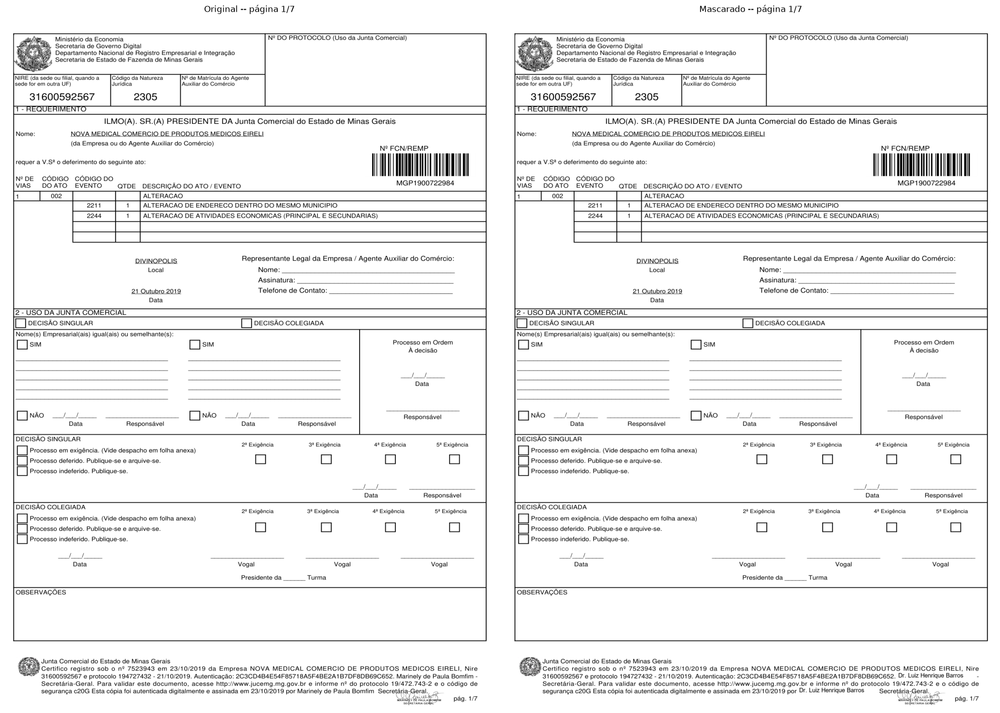

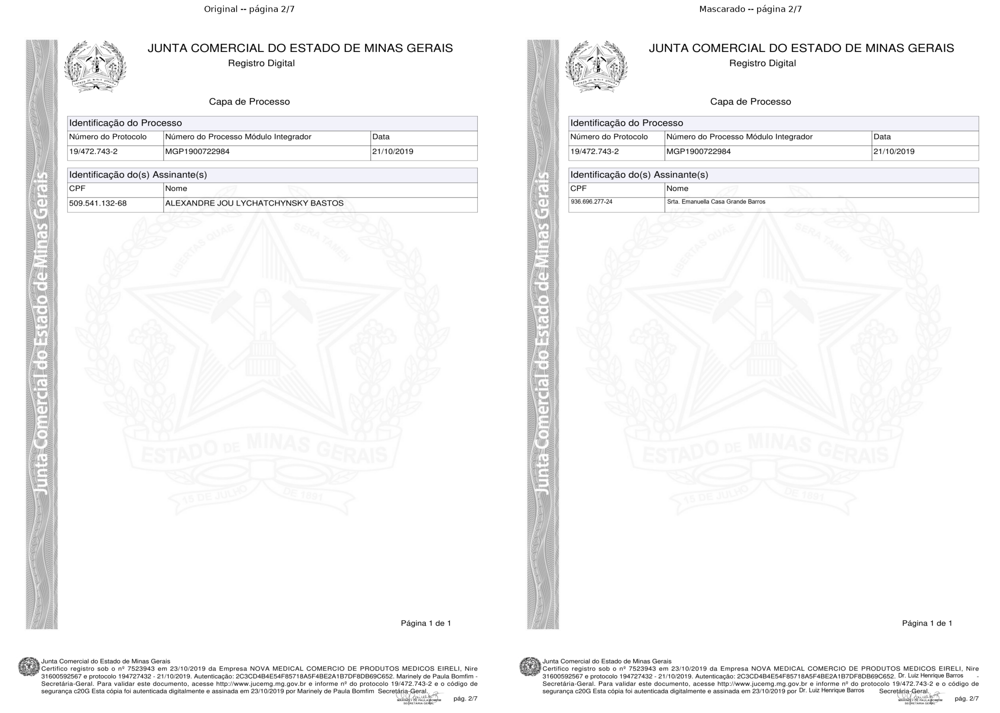

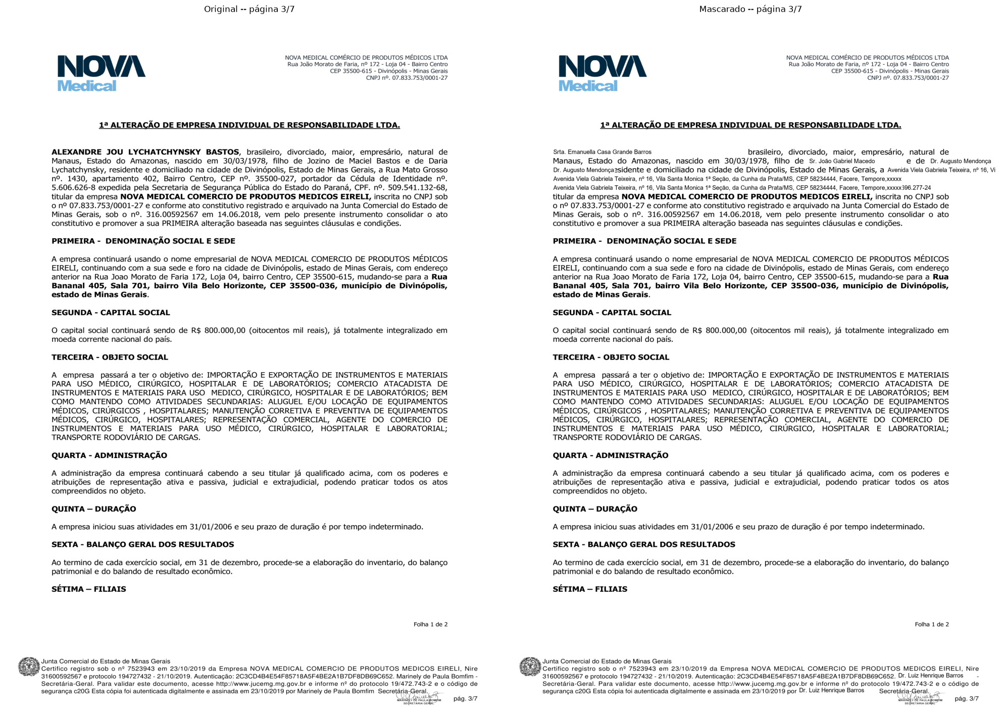

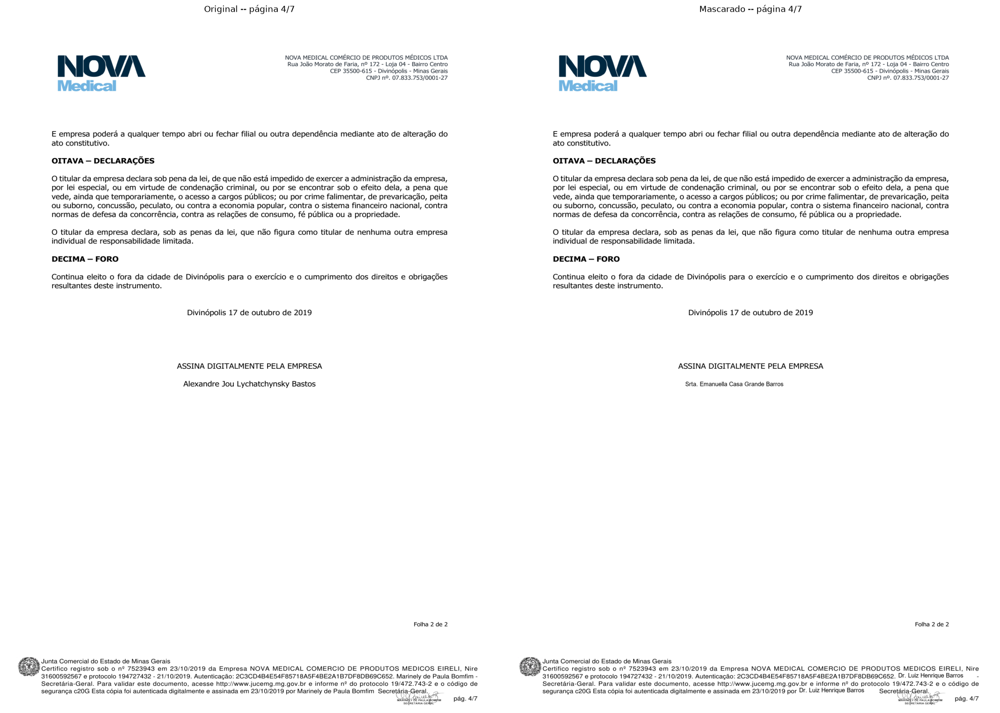

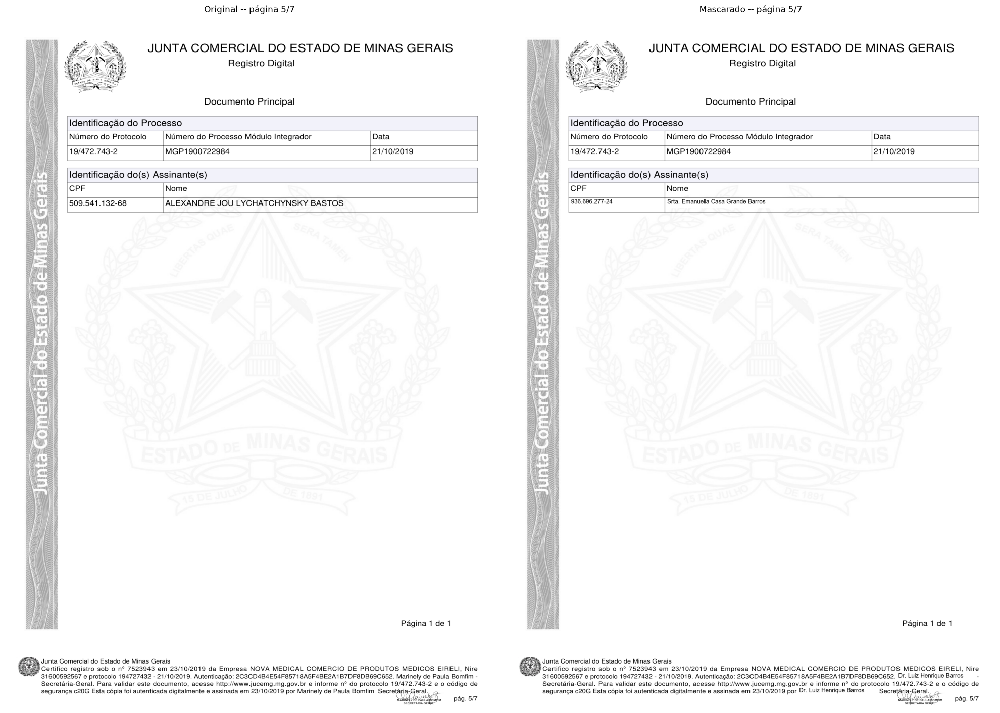

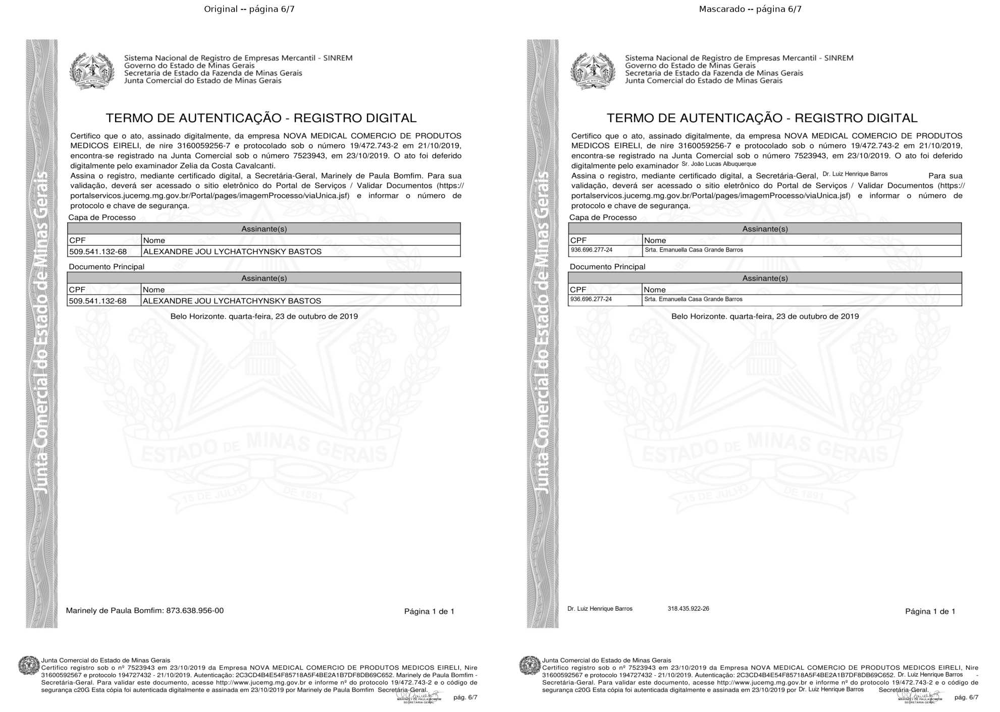

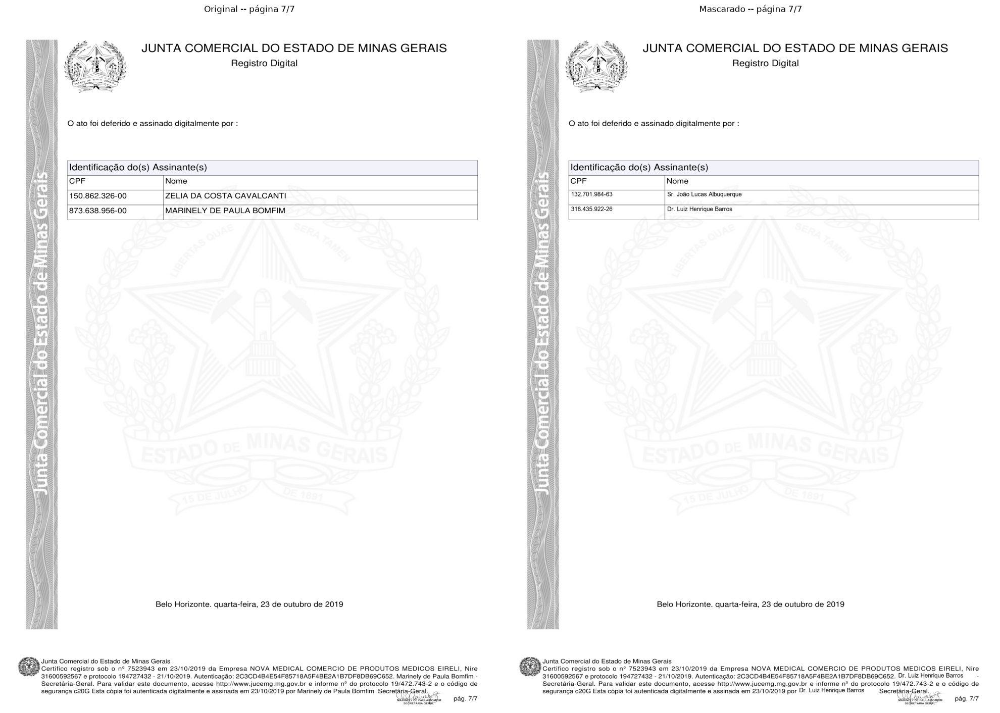

Pergunta: Quem são os sócios da empresa?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO (dados fictícios) ao Gemini (7 página(s))...

PERGUNTA: Quem são os sócios da empresa?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa "NOVA MEDICAL COMERCIO DE PRODUTOS MEDICOS EIRELI" é uma EIRELI (Empresa Individual de Responsabilidade Limitada), o que significa que ela possui um único titular.

De acordo com o documento "1ª ALTERAÇÃO DE EMPRESA INDIVIDUAL DE RESPONSABILIDADE LTDA." (página 3), o **único sócio (titular)** da empresa é:

*   **ALEXANDRE JOU LYCHATCHYNSKY BASTOS** (CPF: 509.541.132-68)


--- RESPOSTA (documento MASCARADO com dados fictícios, já desmascarada) ---

A empresa NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI é uma Empresa Individual de Responsabilidade Limitada (EIRELI), o que significa que ela possui um único titular, e não sócios.

A titular da empresa é:
*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS


--- (

In [28]:
PERGUNTA_EXEMPLO = "Quem são os sócios da empresa?"
resultado_ficticio = perguntar_com_e_sem_mascara_ficticio(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=True)

In [29]:
PERGUNTA_EXEMPLO = "Quais sao os cpfs ou RG dos sócios?"
resultado_ficticio = perguntar_com_e_sem_mascara_ficticio(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quais sao os cpfs ou RG dos sócios?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO (dados fictícios) ao Gemini (7 página(s))...

PERGUNTA: Quais sao os cpfs ou RG dos sócios?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa é uma **EIRELI (Empresa Individual de Responsabilidade Limitada)**, o que significa que possui apenas um titular/sócio.

O CPF e RG do sócio são:

*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS
*   **CPF:** 509.541.132-68
*   **RG:** 5.600.000 (expedida pela Secretaria de Segurança Pública do Estado do Paraná)


--- RESPOSTA (documento MASCARADO com dados fictícios, já desmascarada) ---

A empresa mencionada no documento é uma Empresa Individual de Responsabilidade Limitada (EIRELI), o que significa que ela possui apenas um titular, e não múltiplos sócios.

O CPF e o RG do titular da empresa, ALEXANDRE JOU LYCHATCHYNSKY BASTOS, são:
*   **CPF:** 509.541.132-68
*   **RG:** 150.862.326-00


--- (confe

In [30]:
PERGUNTA_EXEMPLO = "Quais os sócios e seus enderecos?"
resultado_ficticio = perguntar_com_e_sem_mascara_ficticio(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quais os sócios e seus enderecos?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO (dados fictícios) ao Gemini (7 página(s))...

PERGUNTA: Quais os sócios e seus enderecos?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI é uma Empresa Individual de Responsabilidade Limitada (EIRELI), o que significa que ela possui **apenas um único titular (sócio)**.

O sócio e seu endereço são:

*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS
*   **Endereço:** Rua João Morato de Faria, nº 172 – Loja 04 – Bairro Centro, Divinópolis, Minas Gerais, CEP nº 35500-027.

É importante notar que o documento também menciona uma alteração do endereço da **empresa**, que passou para: Rua Bernal 405, Sala 201, Bairro Vila Belo Horizonte, Divinópolis, Minas Gerais, CEP 35500-030. No entanto, o endereço pessoal do sócio, conforme qualificação no documento, é o primeiro listado.


--- RESPOSTA (documento

In [31]:
PERGUNTA_EXEMPLO = "Quem da junta está envolvido nesse documento?"
resultado_ficticio = perguntar_com_e_sem_mascara_ficticio(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quem da junta está envolvido nesse documento?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO (dados fictícios) ao Gemini (7 página(s))...

PERGUNTA: Quem da junta está envolvido nesse documento?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

Da Junta Comercial do Estado de Minas Gerais (JUCEMG), as seguintes pessoas estão envolvidas neste documento:

1.  **Marinely de Paula Bomfim:** Secretária-Geral da JUCEMG, responsável por assinar e registrar o documento mediante certificado digital. (Mencionada na certificação no rodapé de todas as páginas e explicitamente na página 6 e 7).
2.  **Zelia da Costa Cavalcanti:** Examinadora da JUCEMG, responsável por deferir digitalmente o ato. (Mencionada na página 6 e 7).


--- RESPOSTA (documento MASCARADO com dados fictícios, já desmascarada) ---

Os indivíduos da Junta Comercial do Estado de Minas Gerais envolvidos neste documento são:

*   **Zelia da Costa Cavalcanti.**: Secretário-Geral 

In [32]:
PERGUNTA_EXEMPLO = "Gabriel é socio dessa empresa que está no documento?"
resultado_ficticio = perguntar_com_e_sem_mascara_ficticio(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Gabriel é socio dessa empresa que está no documento?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO (dados fictícios) ao Gemini (7 página(s))...

PERGUNTA: Gabriel é socio dessa empresa que está no documento?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

Não, o nome "Gabriel" não aparece no documento como sócio ou titular da empresa.

De acordo com o documento, a empresa é uma **EIRELI (Empresa Individual de Responsabilidade Limitada)**, o que significa que ela possui um único titular.

O titular da empresa **NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI** é **ALEXANDRE JOU LYCHATCHYNSKY BASTOS**, conforme explicitado na página 3 do documento ("1ª ALTERAÇÃO DE EMPRESA INDIVIDUAL DE RESPONSABILIDADE LTDA.").


--- RESPOSTA (documento MASCARADO com dados fictícios, já desmascarada) ---

Não, o nome "Gabriel" não aparece no documento como sócio ou titular da empresa NOVA MEDICAL, COMERCIO DE PRODUTOS MEDICOS EIRELI.

A titular 

## Função: envia a MESMA pergunta ao Gemini duas vezes (original × mascarado) e desmascara a resposta

In [ ]:
def enviar_pergunta_gemini(caminhos_paginas: list, pergunta: str) -> tuple:
    """Envia 1+ imagens (páginas do documento) numa única chamada -- o Gemini as interpreta
    como um documento multi-página."""
    arquivos_remotos = []
    with tempfile.TemporaryDirectory() as tmp_dir:
        for i, caminho in enumerate(caminhos_paginas):
            nome_seguro = f"{i:03d}_" + nome_ascii_seguro(caminho.stem) + caminho.suffix.lower()
            caminho_tmp = Path(tmp_dir) / nome_seguro
            shutil.copyfile(caminho, caminho_tmp)
            arquivo_remoto = client.files.upload(file=str(caminho_tmp))
            while arquivo_remoto.state.name == "PROCESSING":
                time.sleep(2)
                arquivo_remoto = client.files.get(name=arquivo_remoto.name)
            if arquivo_remoto.state.name == "FAILED":
                raise RuntimeError(f"Falha ao processar imagem no Gemini: {caminho}")
            arquivos_remotos.append(arquivo_remoto)

    resposta = client.models.generate_content(
        model=MODEL_GEMINI,
        contents=[*arquivos_remotos, pergunta],
        config=types.GenerateContentConfig(temperature=0),
    )

    texto_resposta = resposta.text
    if not texto_resposta:
        # Achado 2026-09-15: a resposta da versão MASCARADA veio em branco numa execução real --
        # resposta.text pode vir vazio/None sem levantar exceção quando o Gemini não gera texto
        # de verdade (bloqueio de segurança, finish_reason != STOP, ou candidate sem parts).
        # Imprime o diagnóstico completo em vez de devolver "" silenciosamente, pra dar pra ver
        # a causa real na hora (em vez de só constatar "veio vazio" depois).
        print("  [AVISO] resposta.text veio vazia/None -- diagnóstico:")
        feedback = getattr(resposta, "prompt_feedback", None)
        if feedback is not None:
            print(f"    prompt_feedback: {feedback}")
        candidatos = getattr(resposta, "candidates", None) or []
        if not candidatos:
            print("    nenhum candidate na resposta.")
        for i, cand in enumerate(candidatos):
            finish_reason = getattr(cand, "finish_reason", None)
            safety_ratings = getattr(cand, "safety_ratings", None)
            print(f"    candidate[{i}]: finish_reason={finish_reason} safety_ratings={safety_ratings}")
        texto_resposta = texto_resposta or ""

    uso = resposta.usage_metadata
    tokens_entrada = getattr(uso, "prompt_token_count", 0) or 0
    tokens_saida = getattr(uso, "candidates_token_count", 0) or 0
    info_uso = {
        "tokens_entrada": tokens_entrada,
        "tokens_saida": tokens_saida,
        "custo_usd": round(calcular_custo_gemini(MODEL_GEMINI, tokens_entrada, tokens_saida), 5),
    }

    for arquivo_remoto in arquivos_remotos:
        try:
            client.files.delete(name=arquivo_remoto.name)
        except Exception:
            pass

    return texto_resposta, info_uso


def desmascarar_texto(texto: str, catalogo: list) -> str:
    resultado = texto
    for entidade, marcador in catalogo:
        resultado = resultado.replace(marcador, entidade["text"])
    return resultado


_PADRAO_MARCADOR_RESIDUAL = re.compile(r"\[[A-Z]+_[A-Za-z0-9]+\]")


def detectar_marcadores_vazados(texto_pos_desmascaramento: str) -> list:
    """Acha qualquer token com cara de marcador ([TIPO_codigo]) que sobrou DEPOIS do
    desmascaramento -- como desmascarar_texto já substitui todo marcador real do catálogo, tudo
    que sobrar nesse formato não existe no catálogo real (o Gemini inventou um marcador, ou errou
    algum caractere do marcador que recebeu). Achado 2026-09-21: [NOME_YNDMH] vazado numa resposta
    do pro (MINAS CAL) e [ENDERECO_SOCIO]/[ENDERECO_SOCIO_2] inventados pelo flash (documento com
    OCR ruim) -- prompt sozinho não garante que isso nunca aconteça (regra 5 do prompt pede pra
    não inventar marcador, mas é orientação, não trava), então sinaliza automaticamente aqui em
    vez de deixar o texto cru vazar silenciosamente pro usuário final."""
    return _PADRAO_MARCADOR_RESIDUAL.findall(texto_pos_desmascaramento)


def _mostrar_paginas_lado_a_lado(caminhos_originais: list, caminhos_mascarados: list) -> None:
    """Uma figura por página, documento original à esquerda e mascarado à direita -- pra
    comparar visualmente lado a lado em vez de duas sequências separadas."""
    n_paginas = max(len(caminhos_originais), len(caminhos_mascarados))
    for i in range(n_paginas):
        fig, eixos = plt.subplots(1, 2, figsize=(20, 14))
        if i < len(caminhos_originais):
            eixos[0].imshow(Image.open(caminhos_originais[i]))
        eixos[0].axis("off")
        eixos[0].set_title(f"Original -- página {i + 1}/{len(caminhos_originais)}")
        if i < len(caminhos_mascarados):
            eixos[1].imshow(Image.open(caminhos_mascarados[i]))
        eixos[1].axis("off")
        eixos[1].set_title(f"Mascarado -- página {i + 1}/{len(caminhos_mascarados)}")
        plt.tight_layout()
        plt.show()


def perguntar_com_e_sem_mascara(caminho_arquivo: Path, pergunta: str, mostrar_documento: bool = True) -> dict:
    """Envia a MESMA pergunta ao Gemini duas vezes -- uma com o documento original, outra com o
    documento mascarado (com OBSERVACAO_MASCARAMENTO anexada) -- e devolve as duas respostas (a
    mascarada já desmascarada). Recebe (caminho_arquivo, pergunta, mostrar_documento): o catálogo
    de marcadores (variável `catalogo`, célula anterior) já foi calculado uma vez a partir de
    `entidades_documento` e é reaproveitado aqui -- é o que permite chamar esta função várias
    vezes seguidas (uma por pergunta) sem redetectar as entidades nem recalcular o catálogo.

    `mostrar_documento=False` pula a exibição das páginas (original × mascarado lado a lado) --
    útil ao chamar a função várias vezes seguidas pra perguntas diferentes sobre o MESMO
    documento, sem precisar reimprimir as mesmas imagens a cada chamada.

    Imprime (se mostrar_documento=True): as páginas do documento, original e mascarado lado a
    lado por página; e sempre imprime as duas respostas (original e mascarada-desmascarada).
    Nada fica salvo em disco -- as imagens vivem só dentro do diretório temporário desta
    chamada."""
    with tempfile.TemporaryDirectory() as pasta_tmp:
        pasta_tmp = Path(pasta_tmp)
        pasta_original = pasta_tmp / "original"
        pasta_mascarado = pasta_tmp / "mascarado"
        pasta_original.mkdir()
        pasta_mascarado.mkdir()

        caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_original)
        caminhos_mascarados = construir_imagens_mascaradas(caminho_arquivo, catalogo, pasta_mascarado)

        if mostrar_documento:
            _mostrar_paginas_lado_a_lado(caminhos_originais, caminhos_mascarados)

        print(f"Pergunta: {pergunta}")
        print(f"Enviando documento ORIGINAL ao Gemini ({len(caminhos_originais)} página(s))...")
        resposta_original, uso_original = enviar_pergunta_gemini(caminhos_originais, pergunta)

        pergunta_mascarada = OBSERVACAO_MASCARAMENTO.format(
            documento="(as páginas do documento seguem anexadas como imagem(ns), nesta mesma mensagem)",
            pergunta=pergunta,
        ) + (
            "\n\nMapa de páginas por marcador (use isto pra não confundir marcador repetido "
            "com marcador único):\n" + MAPA_PAGINAS_TEXTO
        )
        print(f"Enviando documento MASCARADO ao Gemini ({len(caminhos_mascarados)} página(s))...")
        resposta_mascarada_bruta, uso_mascarado = enviar_pergunta_gemini(caminhos_mascarados, pergunta_mascarada)
        # pasta_tmp (com as imagens originais e mascaradas desta chamada) é apagada ao sair
        # deste "with" -- nada do documento fica salvo em disco depois.

    resposta_mascarada_desmascarada = desmascarar_texto(resposta_mascarada_bruta, catalogo)
    custo_total = uso_original["custo_usd"] + uso_mascarado["custo_usd"]

    print("\n" + "=" * 100)
    print("PERGUNTA:", pergunta)
    print("=" * 100)
    print("\n--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---\n")
    print(resposta_original)
    print("\n" + "=" * 100)
    print("\n--- RESPOSTA (documento MASCARADO, já desmascarada) ---\n")
    print(resposta_mascarada_desmascarada)
    print("\n" + "=" * 100)
    print("\n--- (conferência) RESPOSTA MASCARADA BRUTA, antes de desmascarar ---")
    print("--- confira aqui qual marcador o Gemini usou em cada afirmação -- útil pra diagnosticar")
    print("--- respostas confusas (ex.: mesmo marcador citado com papéis diferentes) ---\n")
    print(resposta_mascarada_bruta)
    print("\n" + "=" * 100)
    print(
        f"\nCusto desta pergunta: US$ {custo_total:.5f} "
        f"(original: US$ {uso_original['custo_usd']:.5f} | mascarado: US$ {uso_mascarado['custo_usd']:.5f})"
    )

    marcadores_vazados = detectar_marcadores_vazados(resposta_mascarada_desmascarada)
    if marcadores_vazados:
        print(f"\n[AVISO] marcador(es) vazado(s) na resposta (não existem no catálogo real): {marcadores_vazados}")

    return {
        "pergunta": pergunta,
        "resposta_original": resposta_original,
        "resposta_mascarada_bruta": resposta_mascarada_bruta,
        "resposta_mascarada_desmascarada": resposta_mascarada_desmascarada,
        "vazamento_marcador": marcadores_vazados,
        "custo_usd": custo_total,
    }


## Uso: chame a função para quantas perguntas quiser

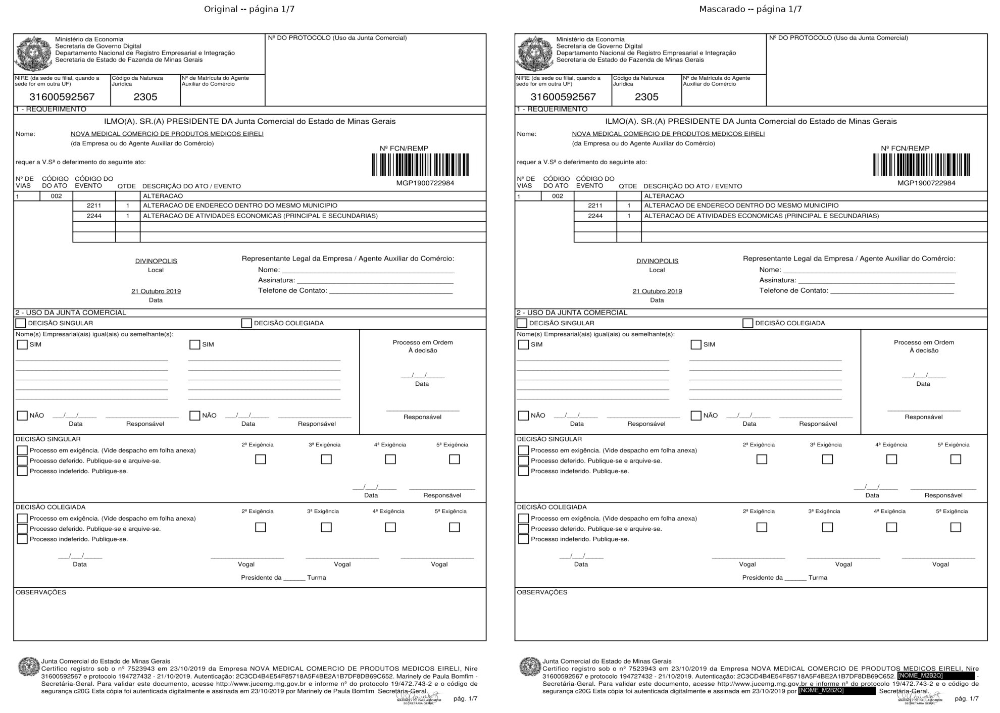

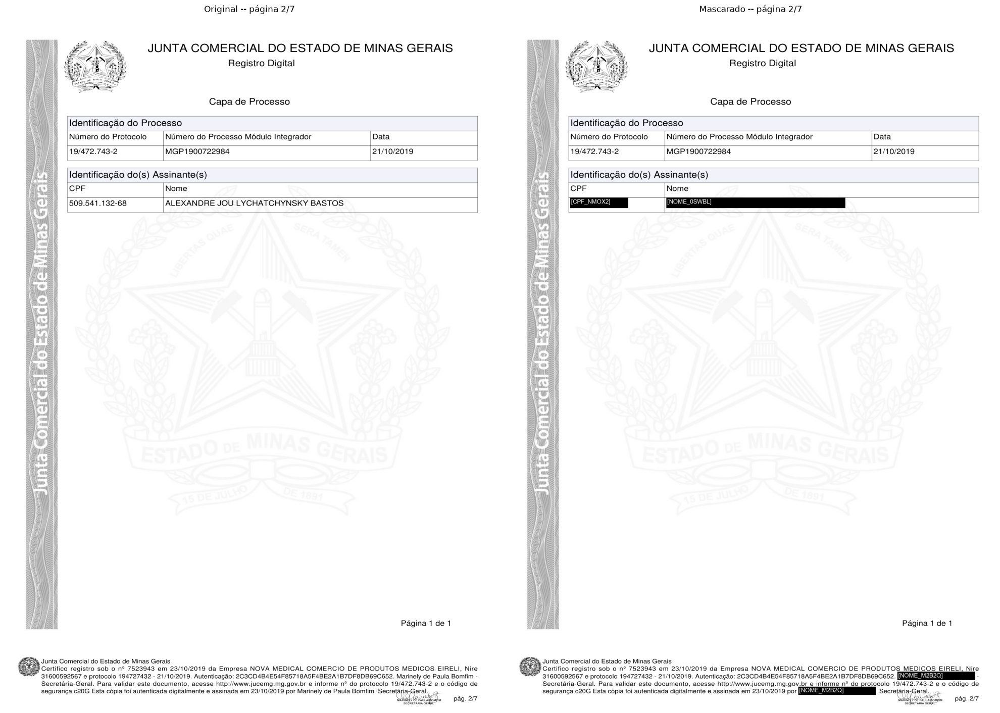

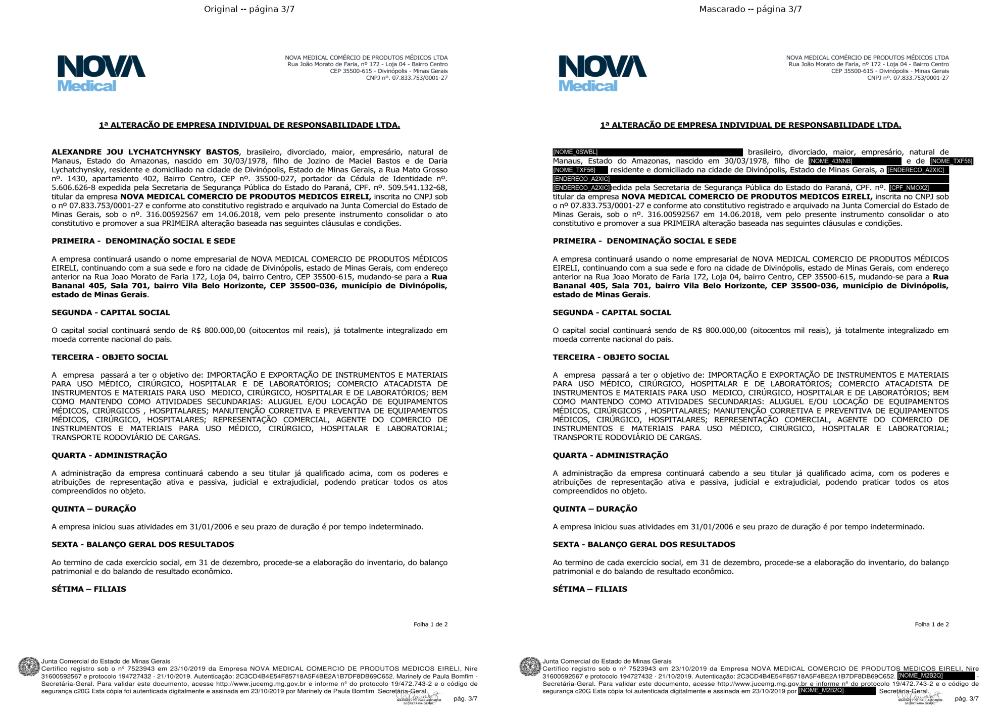

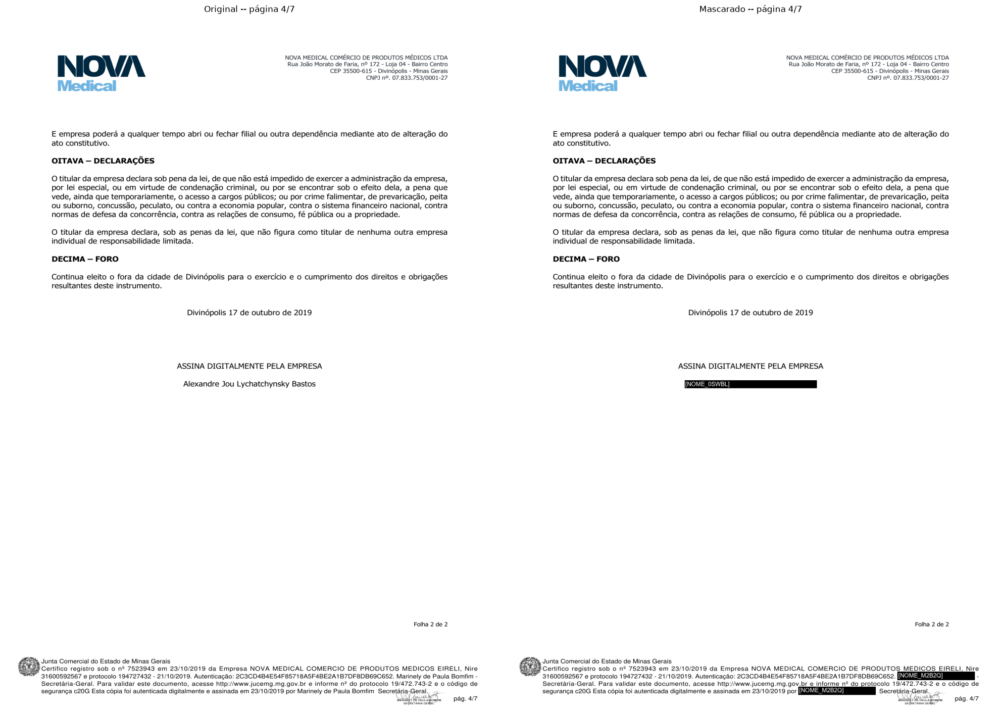

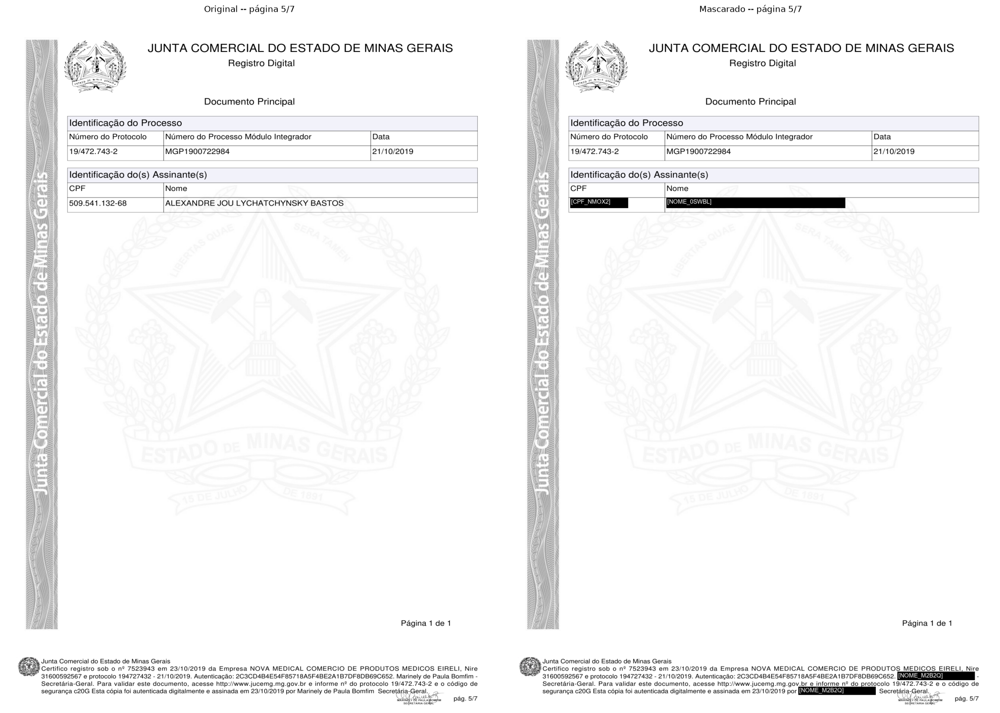

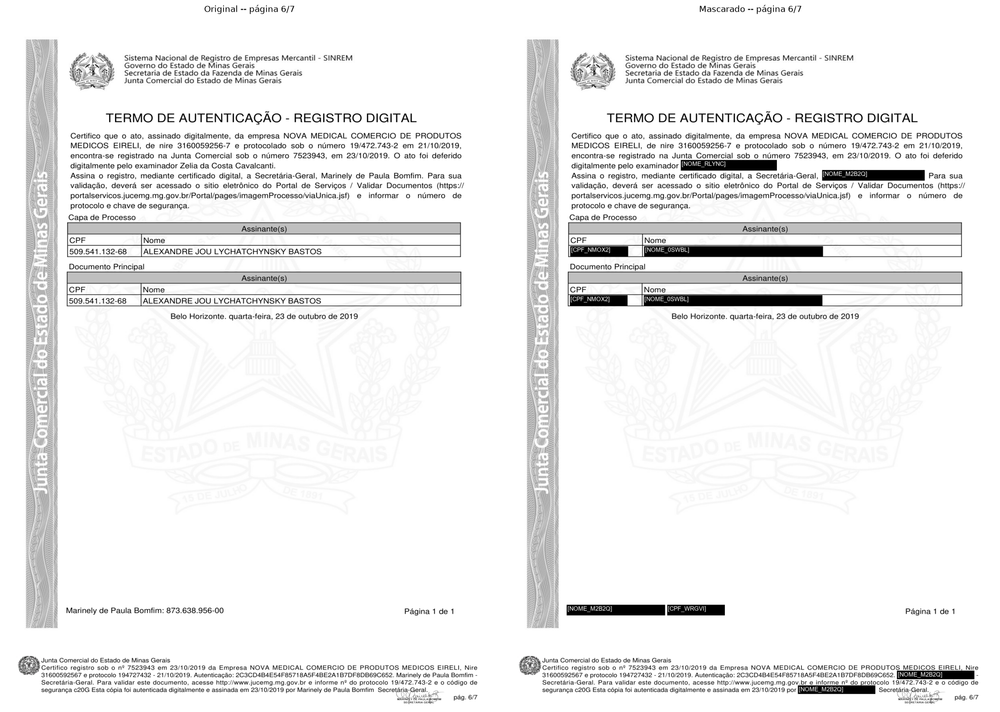

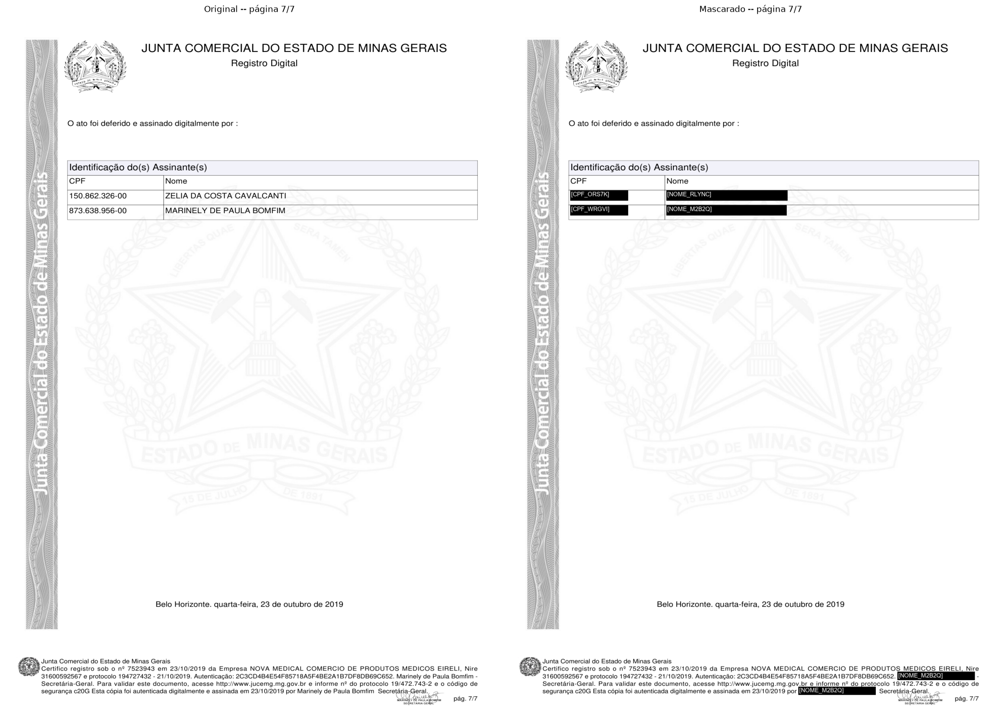

Pergunta: Quem são os sócios da empresa?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO ao Gemini (7 página(s))...

PERGUNTA: Quem são os sócios da empresa?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa **NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI** é uma **Empresa Individual de Responsabilidade Limitada (EIRELI)**.

Por definição, uma EIRELI possui **apenas um titular (sócio)**.

De acordo com o documento, o titular da empresa é:

*   **ALEXANDRE JOU LYCHATCHYNSKY BASTOS** (CPF: 509.541.132-68)


--- RESPOSTA (documento MASCARADO, já desmascarada) ---

O sócio (titular) da empresa é:

*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS
*   **Nacionalidade:** Brasileiro
*   **Estado Civil:** Divorciado
*   **Profissão:** Empresário
*   **Naturalidade:** Daria Lychatchynsky,
*   **Residência:** Divinópolis, Minas Gerais, Rua Mato Grosso nº. 1430, apartamento 402, Bairro Centro, CEP nº. 35500-027, portador da Cédula de Identid

In [34]:
PERGUNTA_EXEMPLO = "Quem são os sócios da empresa?"
resultado = perguntar_com_e_sem_mascara(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=True)

In [35]:
PERGUNTA_EXEMPLO = "Quais sao os cpfs ou RG dos sócios?"
resultado = perguntar_com_e_sem_mascara(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quais sao os cpfs ou RG dos sócios?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO ao Gemini (7 página(s))...

PERGUNTA: Quais sao os cpfs ou RG dos sócios?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa é uma **EIRELI (Empresa Individual de Responsabilidade Limitada)**, o que significa que possui apenas um titular/sócio.

O CPF e RG do sócio são:

*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS
*   **CPF:** 509.541.132-68
*   **RG:** 5.600.000 (expedida pela Secretaria de Segurança Pública do Estado do Paraná)


--- RESPOSTA (documento MASCARADO, já desmascarada) ---

O CPF do titular da empresa (que atua como sócio em uma Empresa Individual de Responsabilidade Limitada) é 509.541.132-68. Não há menção de RG para este titular no documento.


--- (conferência) RESPOSTA MASCARADA BRUTA, antes de desmascarar ---
--- confira aqui qual marcador o Gemini usou em cada afirmação -- útil pra diagnosticar
--- respostas confusa

In [36]:
PERGUNTA_EXEMPLO = "Quais os sócios e seus enderecos?"
resultado = perguntar_com_e_sem_mascara(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quais os sócios e seus enderecos?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO ao Gemini (7 página(s))...

PERGUNTA: Quais os sócios e seus enderecos?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

A empresa NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI é uma Empresa Individual de Responsabilidade Limitada, o que significa que possui um único titular (sócio).

O sócio e seu endereço são:

*   **Nome:** ALEXANDRE JOU LYCHATCHYNSKY BASTOS
*   **Endereço:** Rua João Morato nº 172 - Lojas 04 - Bairro Centro, Divinópolis, Minas Gerais, CEP 35500-027.


--- RESPOSTA (documento MASCARADO, já desmascarada) ---

A empresa em questão é uma EIRELI (Empresa Individual de Responsabilidade Limitada), o que significa que ela possui apenas um titular, e não múltiplos sócios.

O titular da empresa é:
*   **Nome:** MARAUAS
*   **Endereço:** Rua Mato Grosso nº. 1430, apartamento 402, Bairro Centro, CEP nº. 35500-027, portador da Cédula de Ide

In [37]:
PERGUNTA_EXEMPLO = "Quem da junta está envolvido nesse documento?"
resultado = perguntar_com_e_sem_mascara(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Quem da junta está envolvido nesse documento?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO ao Gemini (7 página(s))...

PERGUNTA: Quem da junta está envolvido nesse documento?

--- RESPOSTA (documento ORIGINAL, sem mascaramento) ---

Da Junta Comercial do Estado de Minas Gerais (JUCEMG), as seguintes pessoas estão envolvidas neste documento:

1.  **Marinely de Paula Bomfim:** Secretária-Geral da JUCEMG, responsável por assinar e registrar o documento mediante certificado digital. (Mencionada na certificação no rodapé de todas as páginas e explicitamente na página 6 e 7).
2.  **Zelia da Costa Cavalcanti:** Examinadora da JUCEMG, responsável por deferir digitalmente o ato. (Mencionada na página 6 e 7).


--- RESPOSTA (documento MASCARADO, já desmascarada) ---

Com base no documento, as pessoas da Junta Comercial do Estado de Minas Gerais envolvidas são:

1.  **Zelia da Costa Cavalcanti.**: Examinador(a) que deferiu digitalmente o ato.
2.  *

In [ ]:
PERGUNTA_EXEMPLO = "Gabriel é socio dessa empresa que está no documento?"
resultado = perguntar_com_e_sem_mascara(caminho_arquivo, PERGUNTA_EXEMPLO, mostrar_documento=False)

Pergunta: Gabriel é socio dessa empresa que está no documento?
Enviando documento ORIGINAL ao Gemini (7 página(s))...
Enviando documento MASCARADO ao Gemini (7 página(s))...
